###### TEAM NUMBER: GROUP 11
###### TEAM MEMBERS: SCARLETT SHI, PRABITHA REDDY, HANNA TESHOME
###### SECTION: X2

## Project Objective: Thoroughly explore the provided datasets, analyzing inventory replenishment patterns, and proposing a cost-effective inventory policy.
#### **Methodologies** 
##### For this project we used mulitple libraries such as
##### **numpy:** for numerical operations
##### **matplotlib:** for visualization
##### **matplotlib.dates:** for visualization optimization
##### **datetime:** for calculation of duration
##### **pandas:** for data aggregation and analytics
##### **seaborn:** for drawing the box plot
##### **ROP Analysis:** for the analytics of efficiency operation
##### **EOQ Analysis:** for the analytics of  cost management

## Question 1

### Analyze how well the gas stations manage their fuel inventory and order quantities

**Data Preprocessing**

In [174]:
import pandas as pd 

Fuel_Level_Part_1 = pd.read_csv("Fuel_Level_Part_1-1 (2).csv")
Fuel_Level_Part_2 = pd.read_csv("Fuel_Level_Part_2-1 (1).csv")


**Concatenate Fuel_Level_Part_1.csv and Fuel_Level_Part_2.csv**

In [175]:
#Renaming column names of both the datasets to concatenate them later
Fuel_Level_Part_2 = Fuel_Level_Part_2.rename(columns={"Fuel_Level": "Fuel Level",
                                                      "Timestamp": "Time stamp"
                                                     }
                                            )
display(Fuel_Level_Part_2)

,Tank ID,Fuel Level,Time stamp
0,T 32,22327,1/1/2017 0:05
1,T 20,25215,1/1/2017 0:07
2,T 10,25700,1/1/2017 0:09
3,T 11,25685,1/1/2017 0:10
4,T 14,27138,1/1/2017 0:10
...,...,...,...
974504,T 32,27619,8/15/2019 23:53
974505,T 22,31548,8/15/2019 23:57
974506,T 16,53492,8/15/2019 23:57
974507,T 18,27081,8/15/2019 23:57


In [176]:
#Concatenating Fuel_Level_Part_1.csv and Fuel_Level_Part_2.csv datasets
Fuel_Levels = pd.concat([Fuel_Level_Part_1, Fuel_Level_Part_2])
Fuel_Levels

,Tank ID,Fuel Level,Time stamp
0,T 12,27161.0,1/1/2017 0:10
1,T 12,27017.0,1/1/2017 0:25
2,T 12,26934.0,1/1/2017 0:40
3,T12,NaN,1/1/2017 0:45
4,T 12,26786.0,1/1/2017 0:55
...,...,...,...
974504,T 32,27619.0,8/15/2019 23:53
974505,T 22,31548.0,8/15/2019 23:57
974506,T 16,53492.0,8/15/2019 23:57
974507,T 18,27081.0,8/15/2019 23:57


**Clean datasets and handle missing values**

In [177]:
#handling missing values in the Fuel_Levels dataset
null_values_fuel_levels = Fuel_Levels.isnull().sum()
null_values_fuel_levels

Tank ID       0
Fuel Level    2
Time stamp    0
dtype: int64

In [178]:
#calling the rows with null values to understand how to handle missing values better
Fuel_Levels.shape

(1859660, 3)

In [179]:
#calling the rows with null values to understand how to handle missing values better
null_rows_fuel_levels = Fuel_Levels[Fuel_Levels.isnull().any(axis = 1)]
null_rows_fuel_levels

,Tank ID,Fuel Level,Time stamp
3,T12,NaN,1/1/2017 0:45
111,T12,NaN,1/2/2017 3:35


In [180]:
#Since its just two rows will null values in an entire data set with 1859660 rows of data, we can drop those two rows
Fuel_Levels = Fuel_Levels.dropna()
null_values_fuel_levels = Fuel_Levels.isnull().sum()
null_values_fuel_levels

Tank ID       0
Fuel Level    0
Time stamp    0
dtype: int64

**Merge the Tanks.csv, Locations.csv, and Invoices.csv datasets**

In [181]:
#Merging Tanks.csv, Location.csv, and Invoices.csv datasets
Invoices = pd.read_csv("Invoices-1.csv")
Locations = pd.read_csv("Locations-1.csv")
Tanks = pd.read_csv("Tanks-1.csv")

In [182]:
#Checking for null values in Location
null_values_location = Locations.isnull().sum()
null_values_location

Gas Station Location     0
Gas Station Name         0
Gas Station Address      0
Gas Station Latitude     0
Gas Station Longitude    0
dtype: int64

In [183]:
#Checking for null values in Tanks
null_values_tanks = Tanks.isnull().sum()
null_values_tanks

Tank ID          0
Tank Location    0
Tank Number      0
Tank Type        0
Tank Capacity    0
dtype: int64

In [184]:
#Checking for null values in Tanks
null_values_tanks = Tanks.isnull().sum()
null_values_tanks

Tank ID          0
Tank Location    0
Tank Number      0
Tank Type        0
Tank Capacity    0
dtype: int64

In [185]:
#Checking for null values in Invoices
null_values_invoices = Invoices.isnull().sum()
null_values_invoices

Invoice Date                     0
Invoice ID                      41
Invoice Gas Station Location     0
Gross Purchase Cost             42
Amount Purchased                42
Fuel Type                       42
dtype: int64

In [186]:
#Since crucial information such as invoice date, purchase cost & amount purchased is missing. Lets drop the null values
Invoices = Invoices.dropna()
#initiating a check again 
null_values_invoices = Invoices.isnull().sum()
null_values_invoices

Invoice Date                    0
Invoice ID                      0
Invoice Gas Station Location    0
Gross Purchase Cost             0
Amount Purchased                0
Fuel Type                       0
dtype: int64

In [187]:
#Renaming the common columns in all three datasets to one common name for the purpose of merging
Invoices = Invoices.rename(columns={"Invoice Gas Station Location": "Gas Station Location"})
display(Invoices)

,Invoice Date,Invoice ID,Gas Station Location,Gross Purchase Cost,Amount Purchased,Fuel Type
0,1/2/2017,10000.0,1,7570.82000,6609.600,G
1,1/2/2017,10001.0,1,12491.85300,9338.736,D
3,1/2/2017,10002.0,2,17034.34500,13377.824,D
5,1/2/2017,10003.0,2,12616.77153,9432.112,D
6,1/2/2017,10004.0,4,11363.80082,9139.200,D
...,...,...,...,...,...,...
2868,8/14/2019,12826.0,2,14418.62669,8182.960,D
2869,8/14/2019,12827.0,2,7570.82000,4296.640,D
2870,8/14/2019,12828.0,4,8706.44300,6352.416,G
2871,8/14/2019,12829.0,4,13252.72041,7521.264,D


In [188]:
Tanks = Tanks.rename(columns={"Tank Location": "Gas Station Location"})
display(Tanks)

,Tank ID,Gas Station Location,Tank Number,Tank Type,Tank Capacity
0,T 10,1,1,U,40000
1,T 11,1,2,U,40000
2,T 12,1,3,D,40000
3,T 13,1,4,P,40000
4,T 14,1,5,U,40000
5,T 15,1,6,D,40000
6,T 16,2,1,U,70000
7,T 17,2,2,D,40000
8,T 18,2,3,U,40000
9,T 19,2,4,D,70000


In [189]:
Invoices = Invoices.merge(Locations, on =  'Gas Station Location', how = 'inner')
display(Invoices)

,Invoice Date,Invoice ID,Gas Station Location,Gross Purchase Cost,Amount Purchased,Fuel Type,Gas Station Name,Gas Station Address,Gas Station Latitude,Gas Station Longitude
0,1/2/2017,10000.0,1,7570.82000,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.234670,-79.836510
1,1/2/2017,10001.0,1,12491.85300,9338.736,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.234670,-79.836510
2,1/2/2017,10002.0,2,17034.34500,13377.824,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930
3,1/2/2017,10003.0,2,12616.77153,9432.112,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930
4,1/2/2017,10004.0,4,11363.80082,9139.200,D,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057
...,...,...,...,...,...,...,...,...,...,...
2826,8/14/2019,12826.0,2,14418.62669,8182.960,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930
2827,8/14/2019,12827.0,2,7570.82000,4296.640,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930
2828,8/14/2019,12828.0,4,8706.44300,6352.416,G,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057
2829,8/14/2019,12829.0,4,13252.72041,7521.264,D,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057


In [190]:
Updated_Invoices = Invoices.merge(Tanks, on =  'Gas Station Location', how = 'inner')
display(Updated_Invoices)

,Invoice Date,Invoice ID,Gas Station Location,Gross Purchase Cost,Amount Purchased,Fuel Type,Gas Station Name,Gas Station Address,Gas Station Latitude,Gas Station Longitude,Tank ID,Tank Number,Tank Type,Tank Capacity
0,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 10,1,U,40000
1,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 11,2,U,40000
2,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 12,3,D,40000
3,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 13,4,P,40000
4,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 14,5,U,40000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12407,8/15/2019,12830.0,1,8327.902,4692.864,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 11,2,U,40000
12408,8/15/2019,12830.0,1,8327.902,4692.864,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 12,3,D,40000
12409,8/15/2019,12830.0,1,8327.902,4692.864,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 13,4,P,40000
12410,8/15/2019,12830.0,1,8327.902,4692.864,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 14,5,U,40000


**Cleaning the dataset**

In [191]:
#Replacing U & P with G (Tank Type) in the dataset
Updated_Invoices["Tank Type"] = Updated_Invoices["Tank Type"].replace({"U": "G",
                                                                        "P": "G"
                                                                       }
                                                                      )
display(Updated_Invoices)

,Invoice Date,Invoice ID,Gas Station Location,Gross Purchase Cost,Amount Purchased,Fuel Type,Gas Station Name,Gas Station Address,Gas Station Latitude,Gas Station Longitude,Tank ID,Tank Number,Tank Type,Tank Capacity
0,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 10,1,G,40000
1,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 11,2,G,40000
2,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 12,3,D,40000
3,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 13,4,G,40000
4,1/2/2017,10000.0,1,7570.820,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 14,5,G,40000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12407,8/15/2019,12830.0,1,8327.902,4692.864,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 11,2,G,40000
12408,8/15/2019,12830.0,1,8327.902,4692.864,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 12,3,D,40000
12409,8/15/2019,12830.0,1,8327.902,4692.864,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 13,4,G,40000
12410,8/15/2019,12830.0,1,8327.902,4692.864,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.23467,-79.83651,T 14,5,G,40000


In [192]:
#verifying all the data types: for Updated Invoices
#conclusion:should change the Invoice ID dtype to int64
print(Updated_Invoices.dtypes)

Invoice Date              object
Invoice ID               float64
Gas Station Location       int64
Gross Purchase Cost      float64
Amount Purchased         float64
Fuel Type                 object
Gas Station Name          object
Gas Station Address       object
Gas Station Latitude     float64
Gas Station Longitude    float64
Tank ID                   object
Tank Number                int64
Tank Type                 object
Tank Capacity              int64
dtype: object


In [193]:
#Changing the data type of Invoice ID to int64
Updated_Invoices["Invoice ID"] = Updated_Invoices["Invoice ID"].astype(int)
print(Updated_Invoices.dtypes)

Invoice Date              object
Invoice ID                 int64
Gas Station Location       int64
Gross Purchase Cost      float64
Amount Purchased         float64
Fuel Type                 object
Gas Station Name          object
Gas Station Address       object
Gas Station Latitude     float64
Gas Station Longitude    float64
Tank ID                   object
Tank Number                int64
Tank Type                 object
Tank Capacity              int64
dtype: object


In [194]:
#Verifying all the data types: for Fuel Levels
print(Fuel_Levels.dtypes)

Tank ID        object
Fuel Level    float64
Time stamp     object
dtype: object


In [195]:
#Removing duplicates, if any: for Updated Invoices
Updated_Invoices_wo_d = Updated_Invoices.drop_duplicates()

In [196]:
Updated_Invoices_wo_d.shape

(12412, 14)

In [197]:
#There were no duplicates in the dataset
Updated_Invoices.shape

(12412, 14)

In [198]:
#Removing duplicates, if any: for Fuel Levels
Fuel_Levels_wo_d = Fuel_Levels.drop_duplicates()

In [199]:
Fuel_Levels_wo_d.shape

(1859587, 3)

In [200]:
#there were duplicates for the dataset Fuel Levels
Fuel_Levels.shape

(1859658, 3)

*During our initial exploratory analysis, we found no inconsistencies within the datasets. There is also no need to encode any variables as there aren't any categorical variables. At this stage, we don't see the need for standardisation or normalization. At this stage, we also believe that the presence of outliers is important in our analysis. Thus, we wont be treating for outliers in our python cleaning step.*

**Create visualizations for each tank to assess inventory trends over time. Identify stations with
effective inventory management practices and those at risk of stockouts**

**DATA VISUALIZATION**

In [201]:
Fuel_Levels_wo_d.head()

,Tank ID,Fuel Level,Time stamp
0,T 12,27161.0,1/1/2017 0:10
1,T 12,27017.0,1/1/2017 0:25
2,T 12,26934.0,1/1/2017 0:40
4,T 12,26786.0,1/1/2017 0:55
5,T 12,26748.0,1/1/2017 1:10


In [202]:
#Figure out which Tank do we have and then visualize their inventory data one by one.
Fuel_Levels_wo_d['Tank ID'].unique()

array(['T 12', 'T 13', 'T 15', 'T 17', 'T 19', 'T 21', 'T 23', 'T 24',
       'T 28', 'T 30', 'T 31', 'T 32', 'T 20', 'T 10', 'T 11', 'T 14',
       'T 25', 'T 16', 'T 27', 'T 26', 'T 22', 'T 18', 'T 29'],
      dtype=object)

**Create a reusable function that filters and plots each tank**

In [203]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def trend(df, tank_id, times='Time stamp', fuels='Fuel Level', tank_name=None):
    if tank_name is None:
        tank_name = tank_id
    
    # Filter tank and copy
    tank_df = df[df['Tank ID'] == tank_id].copy()
    
    # Rename timestamp column
    tank_df = tank_df.rename(columns={times: 'Time_Stamp'})
    
    # Extract date
    tank_df['date'] = tank_df['Time_Stamp'].str.split(' ').str[0]
    
    # Aggregate to daily minimum
    tank_min = tank_df.groupby('date', as_index=False)[fuels].min()
    
    # Convert date to datetime and sort
    tank_min['date'] = pd.to_datetime(tank_min['date'])
    tank_min = tank_min.sort_values('date', ascending=True)
    
    # Remove NA
    valid_df = tank_min[tank_min[fuels].notna()]
    
    # Plot
    plt.figure(figsize=(25,5))
    plt.plot(valid_df['date'], valid_df[fuels], color='steelblue', label='Inventory')
    plt.title(f'Inventory Trend of {tank_name}', fontsize=20)
    plt.xlabel('Time', fontsize=12)
    plt.ylabel('Fuel Level (L)', fontsize=12)
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    # Format x-axis for monthly ticks
    months = mdates.MonthLocator(interval=1)
    months_fmt = mdates.DateFormatter('%Y-%m')
    axis = plt.gca()
    axis.xaxis.set_major_locator(months)
    axis.xaxis.set_major_formatter(months_fmt)
    
    plt.legend()
    plt.show()

**Visualization For T10**

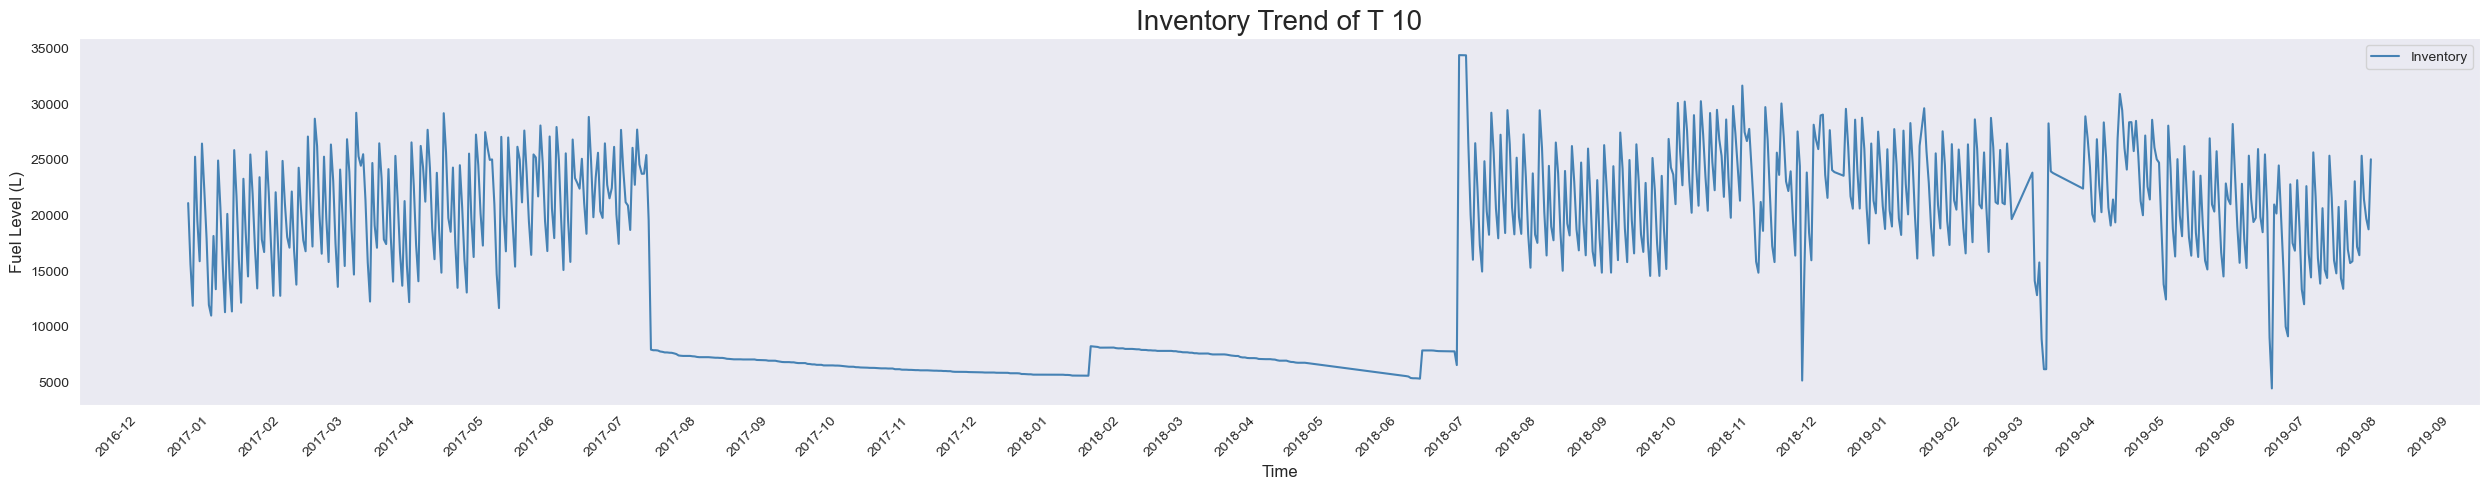

In [204]:
#We decided if the tank inventory is effetive if its following consistent pattens and is not at risk of stockout often.
#Risk of stockout, long period with no inventory refill
trend(Fuel_Levels_wo_d, 'T 10') #risk of stockout, long period with no inventory refill

**Visualization For T11**

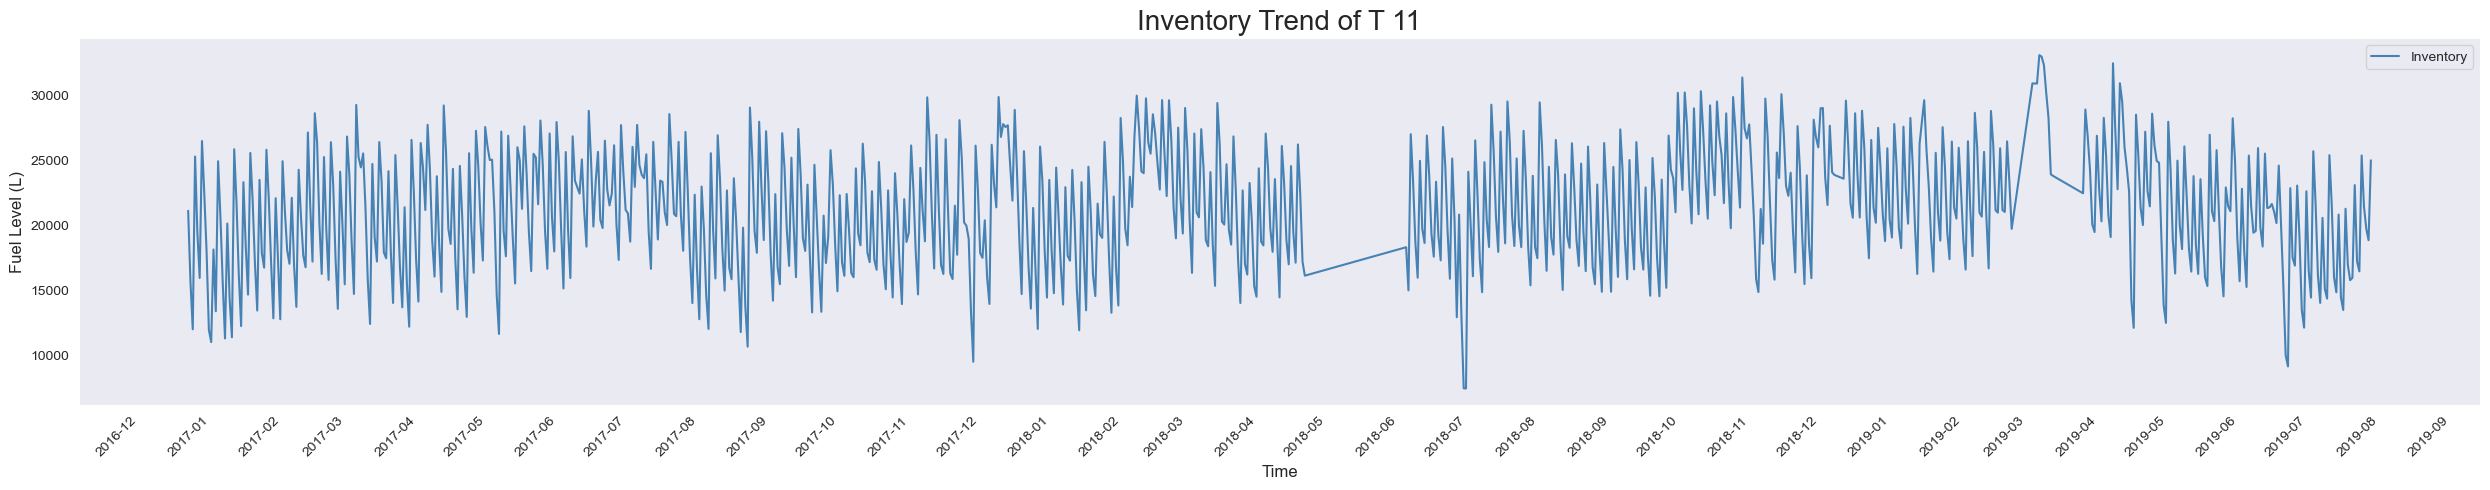

In [205]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 11')

**Visualization For T12**

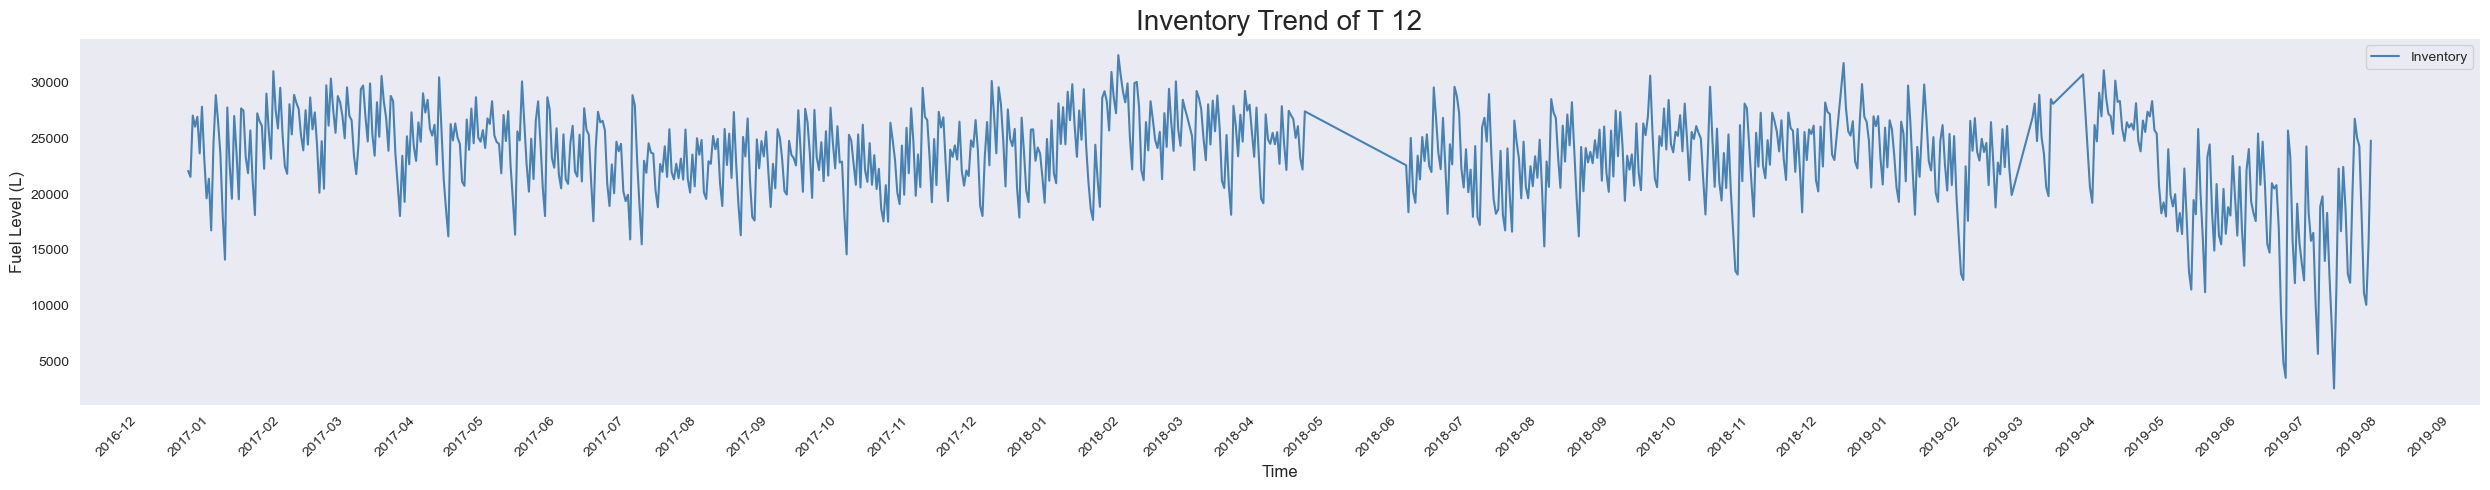

In [206]:
#Risk of stockout towards end of the graph
trend(Fuel_Levels_wo_d, 'T 12') 

**Visualization For T13**

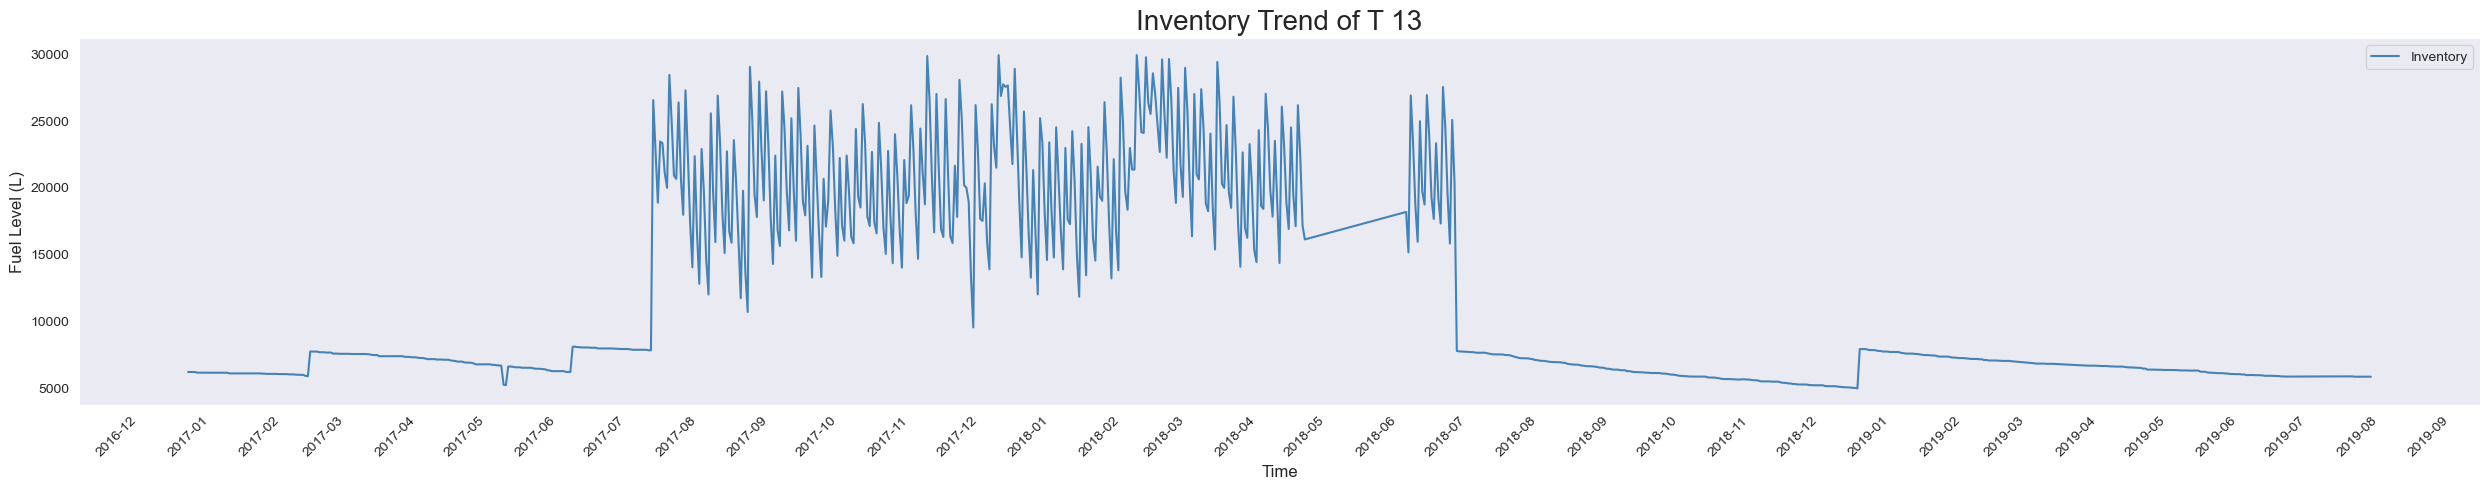

In [207]:
#Risk stockout start and end of graph
trend(Fuel_Levels_wo_d, 'T 13')

**Visualization For T14**

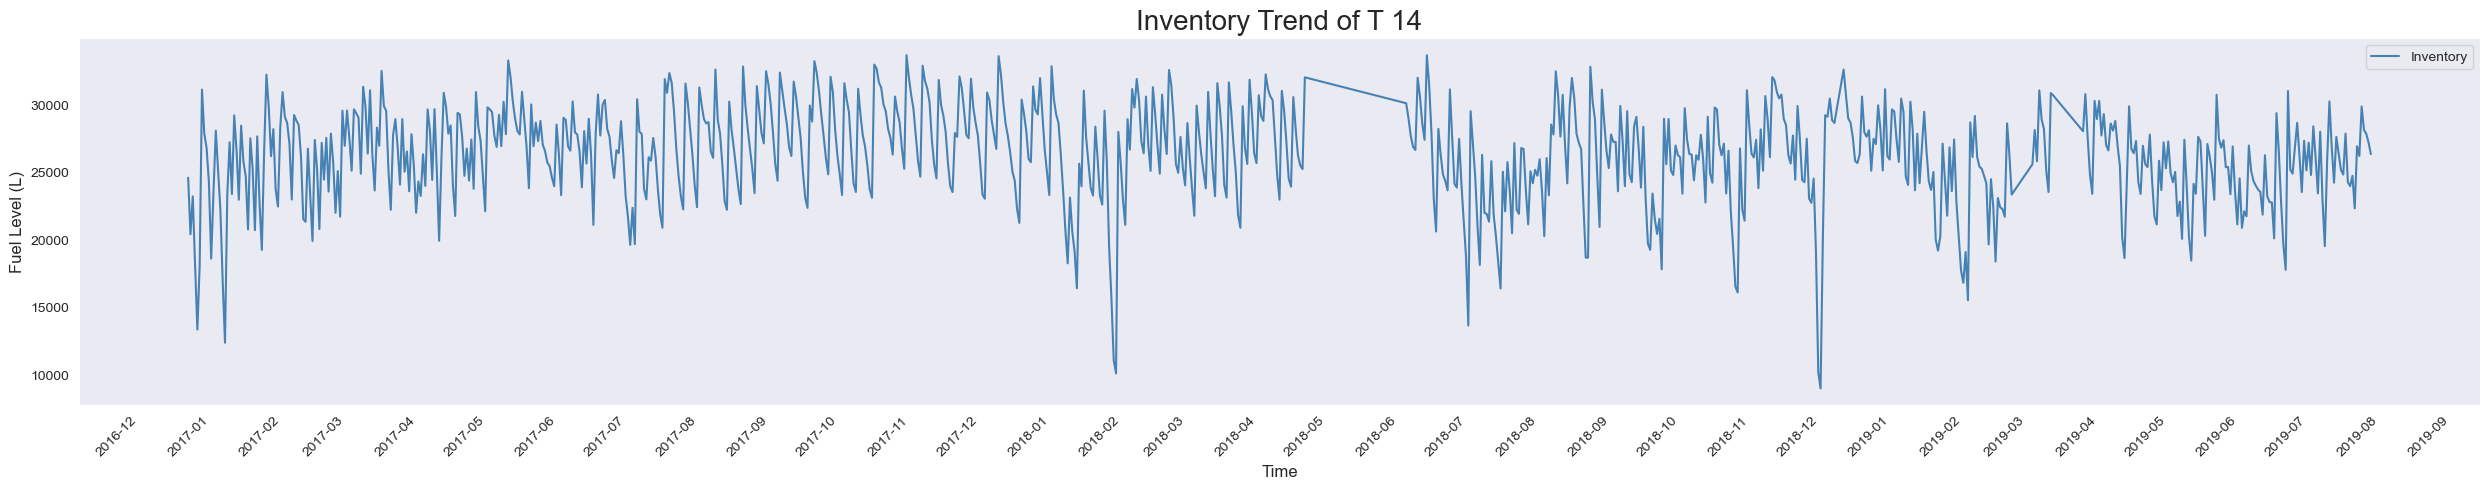

In [208]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 14')

**Visualization For T15**

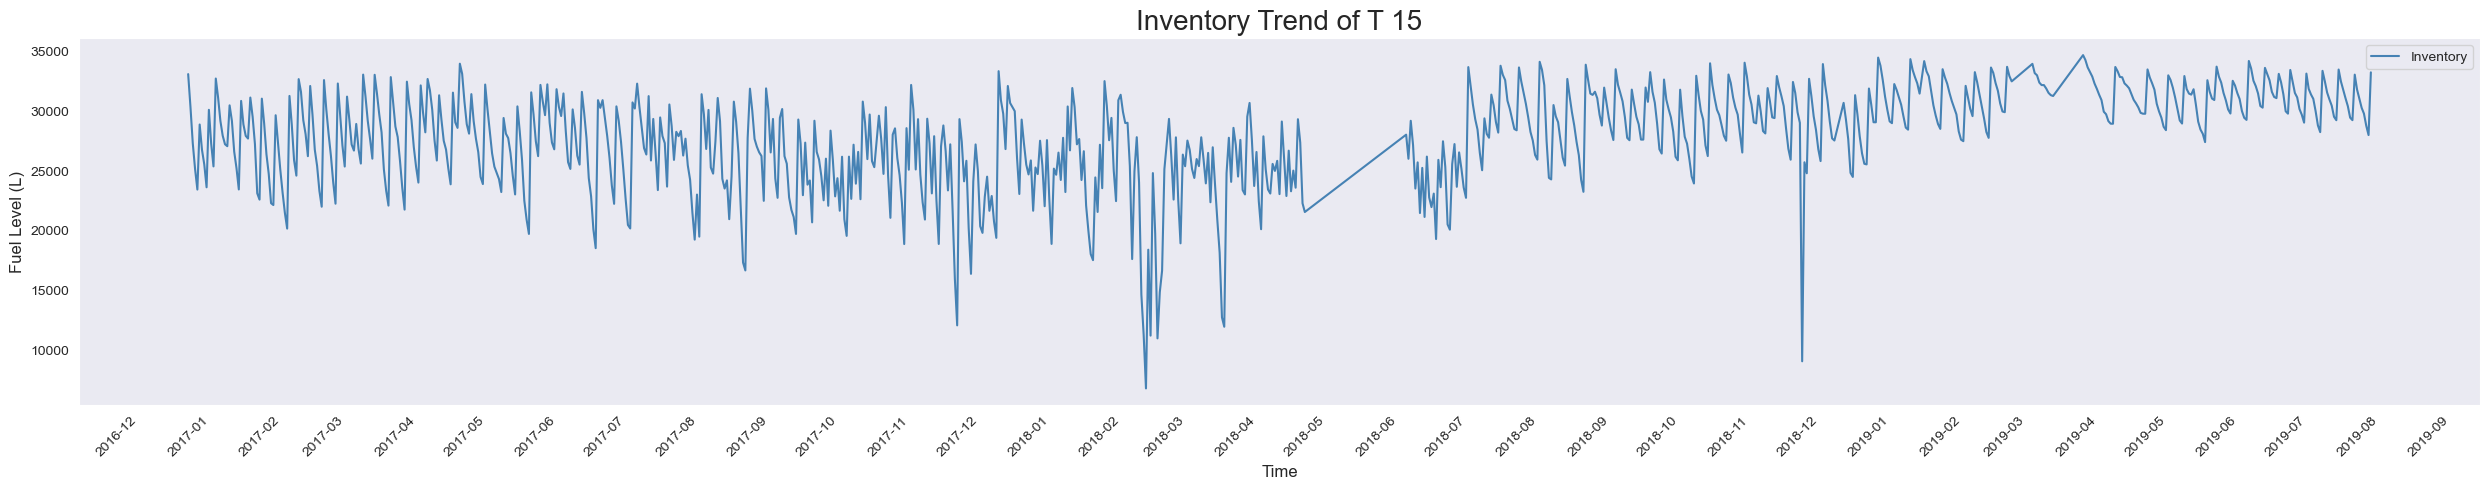

In [209]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 15')

**Visualization For T16**

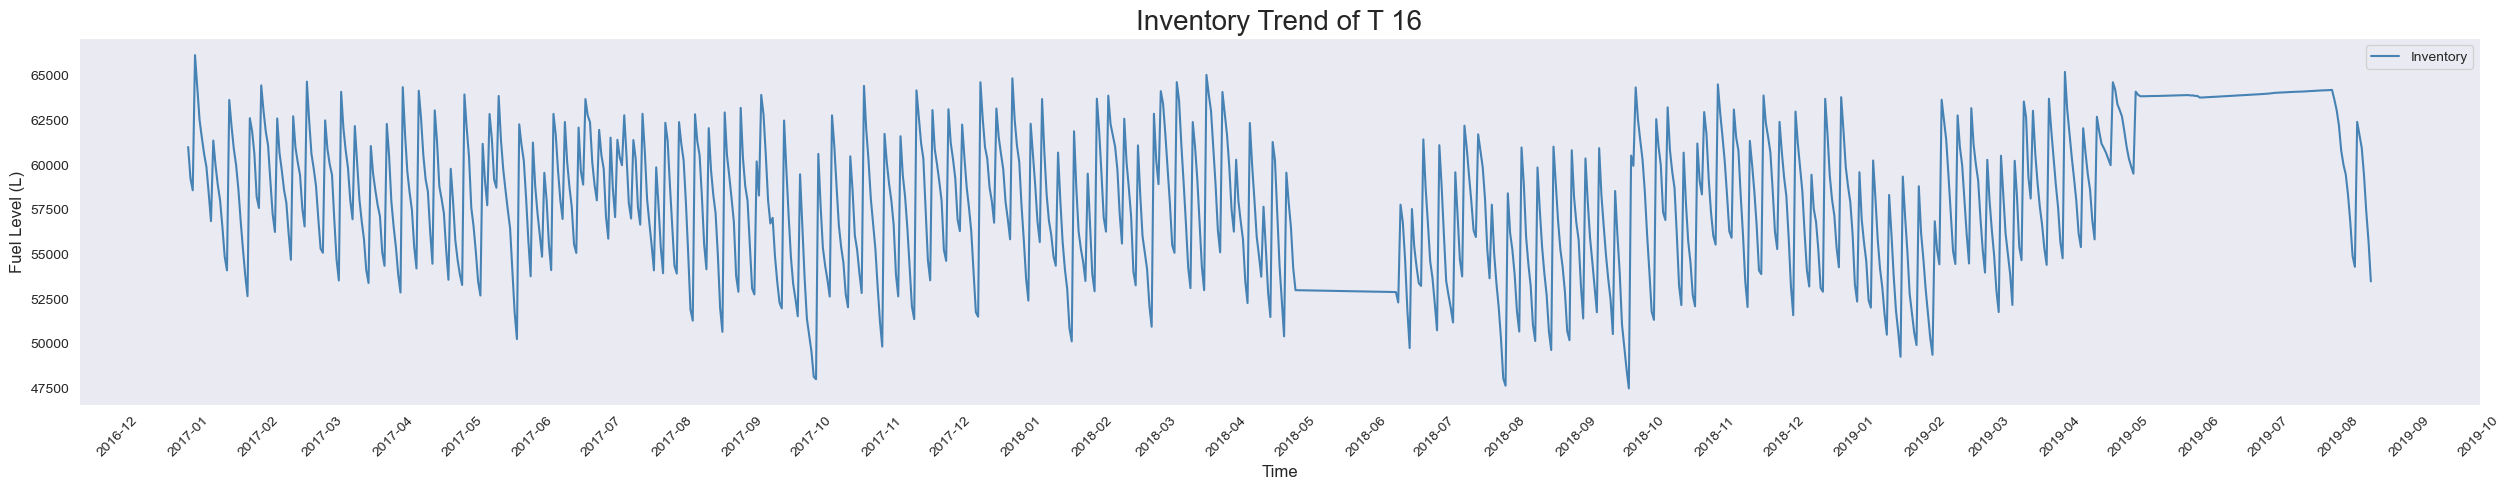

In [210]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 16')

**Visualization For T17**

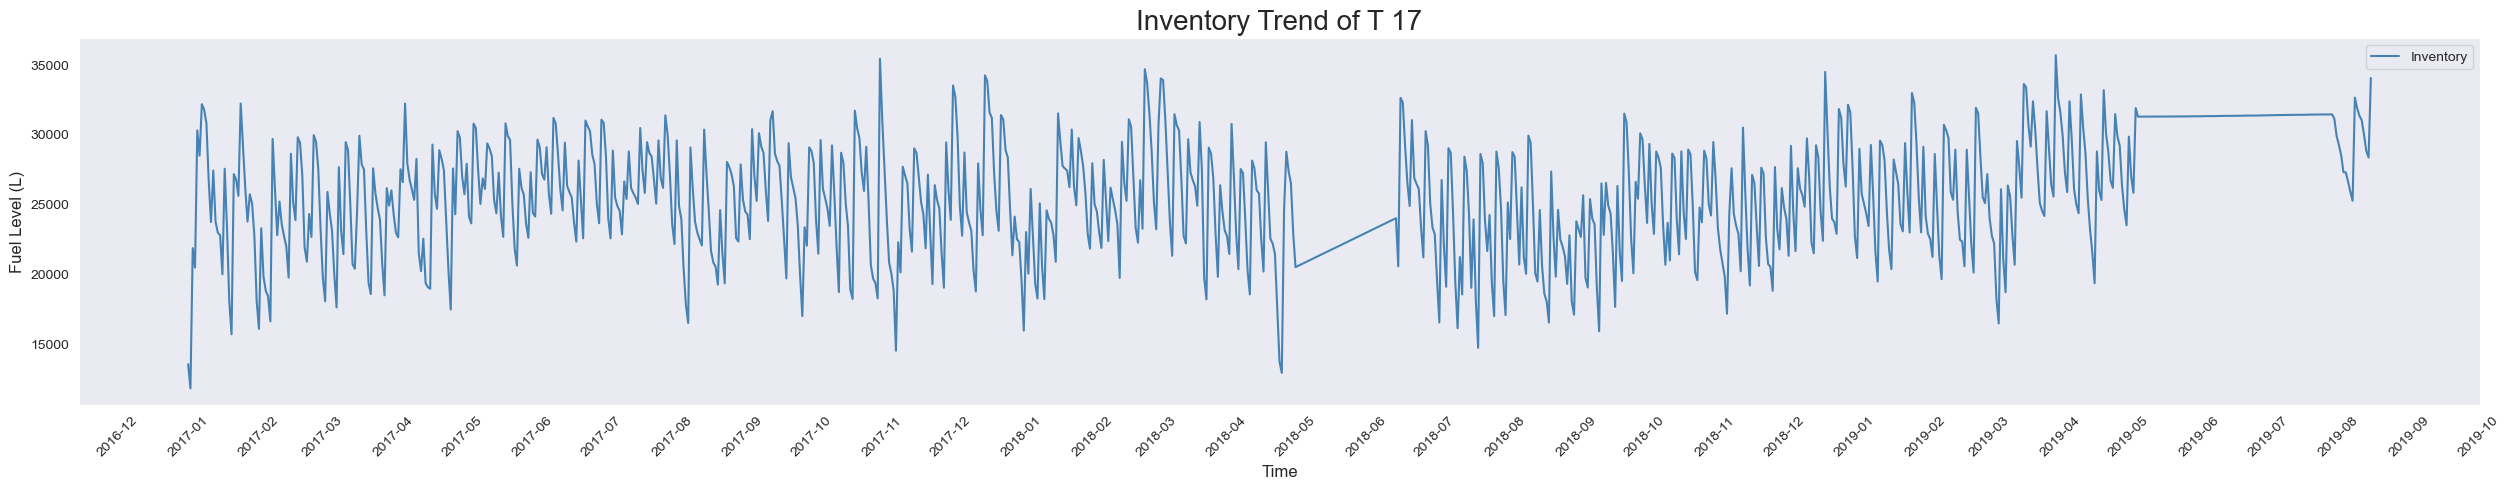

In [211]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 17')

**Visualization For T18**

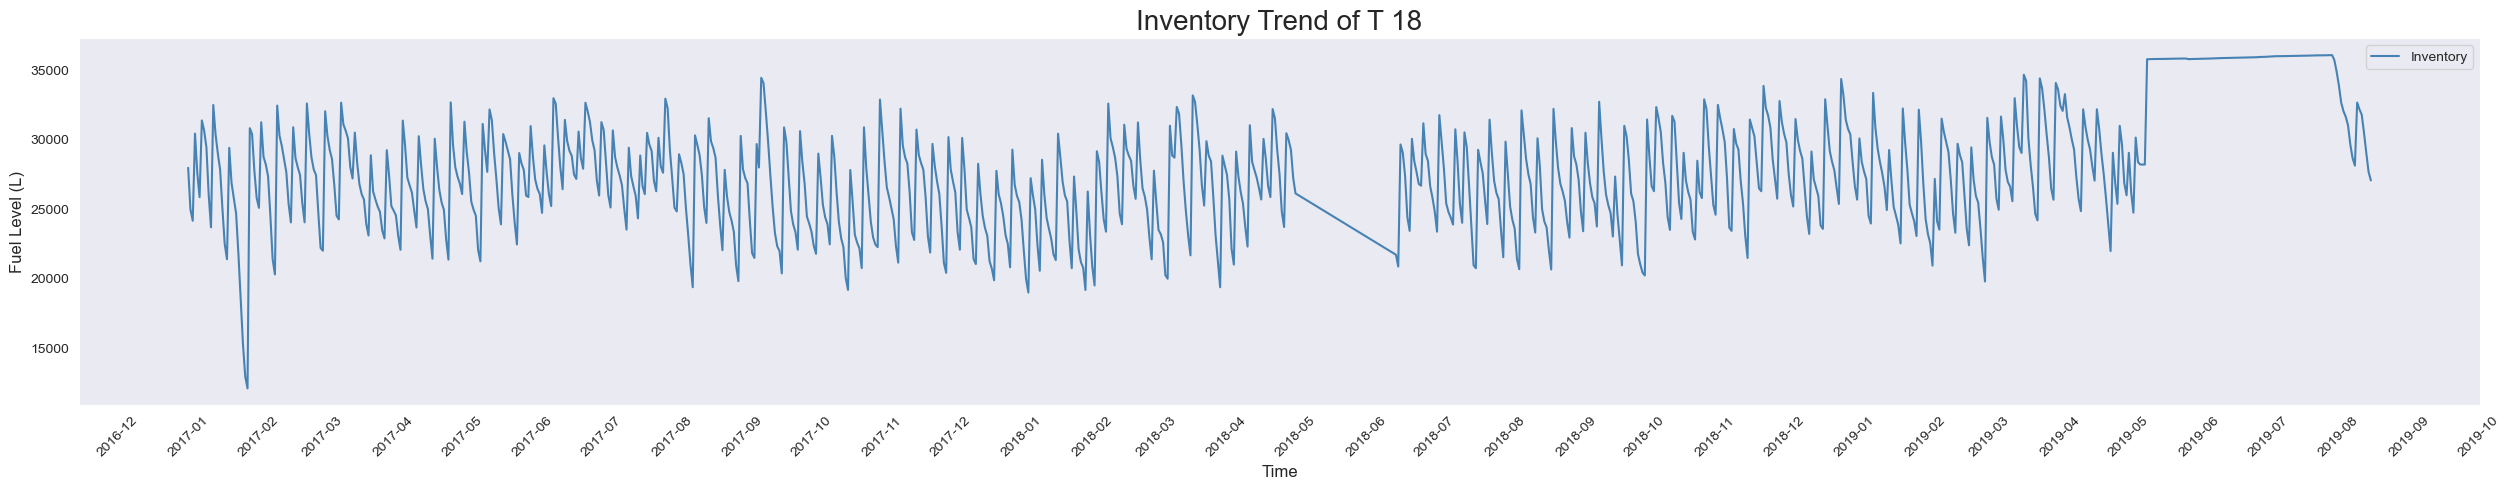

In [212]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 18')

**Visualization For T19**

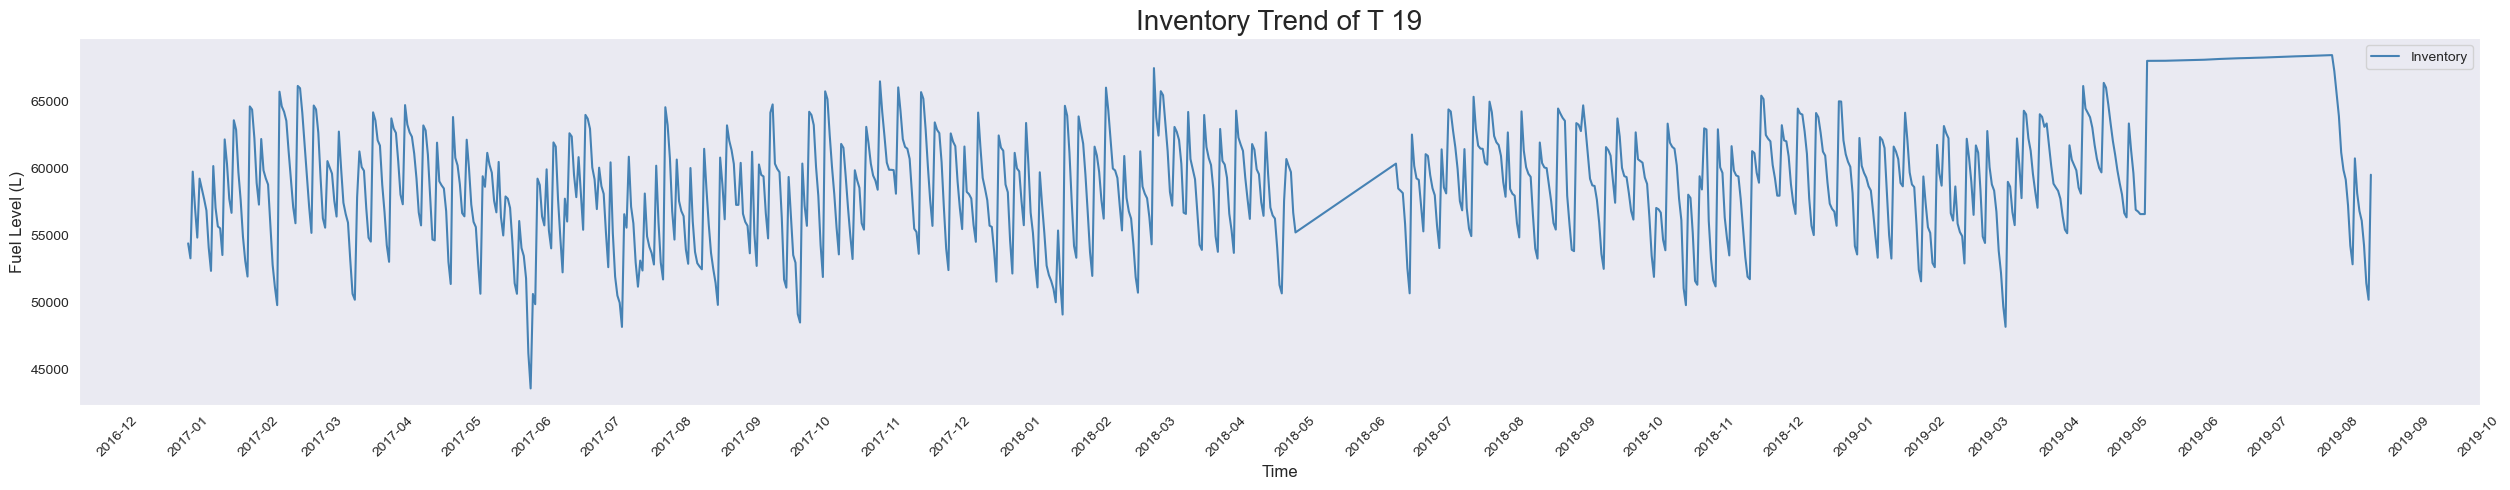

In [213]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 19')

**Visualization For T20**

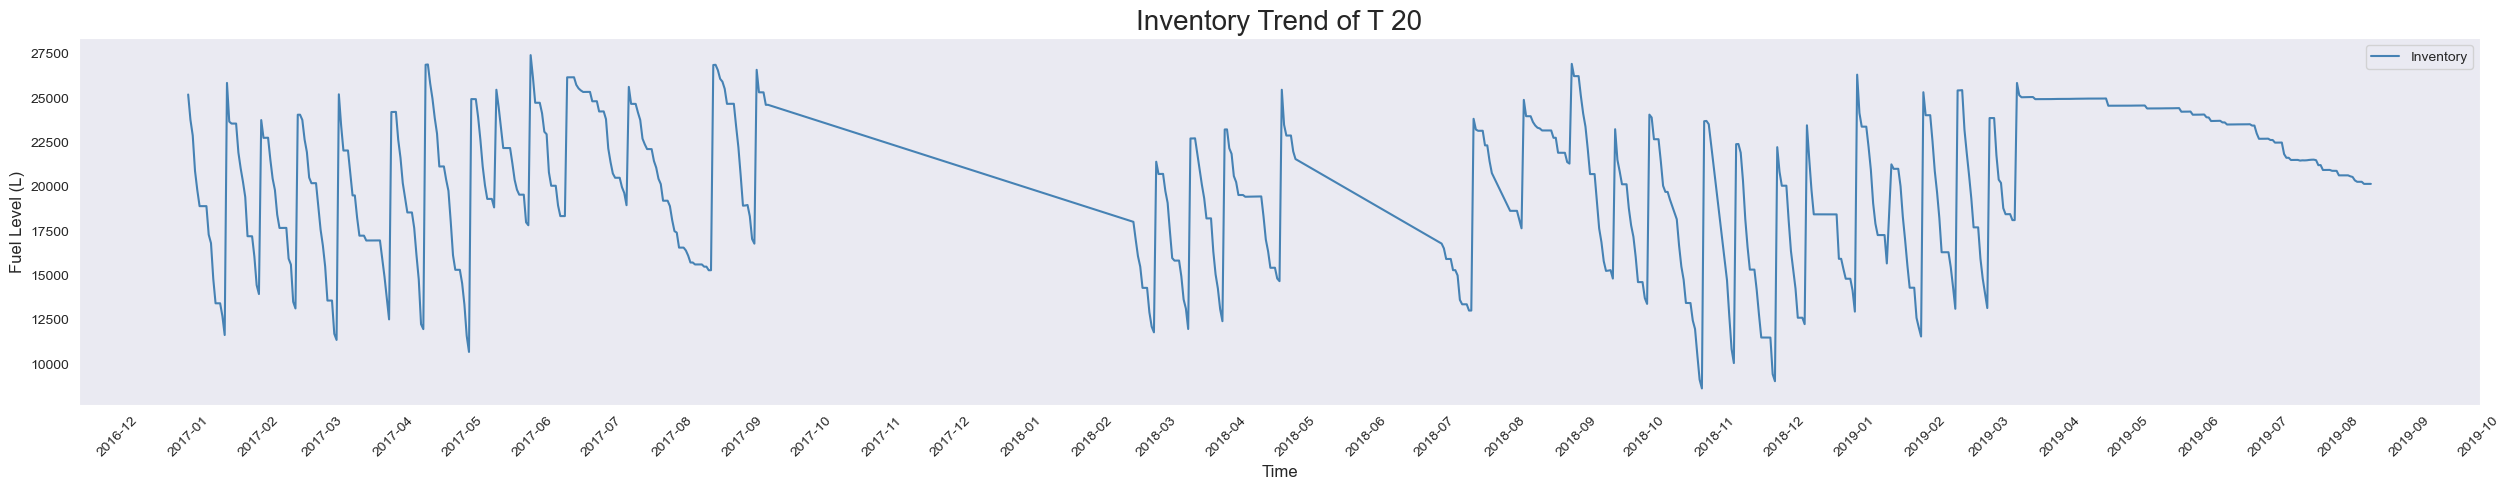

In [214]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 20')

**Visualization For T21**

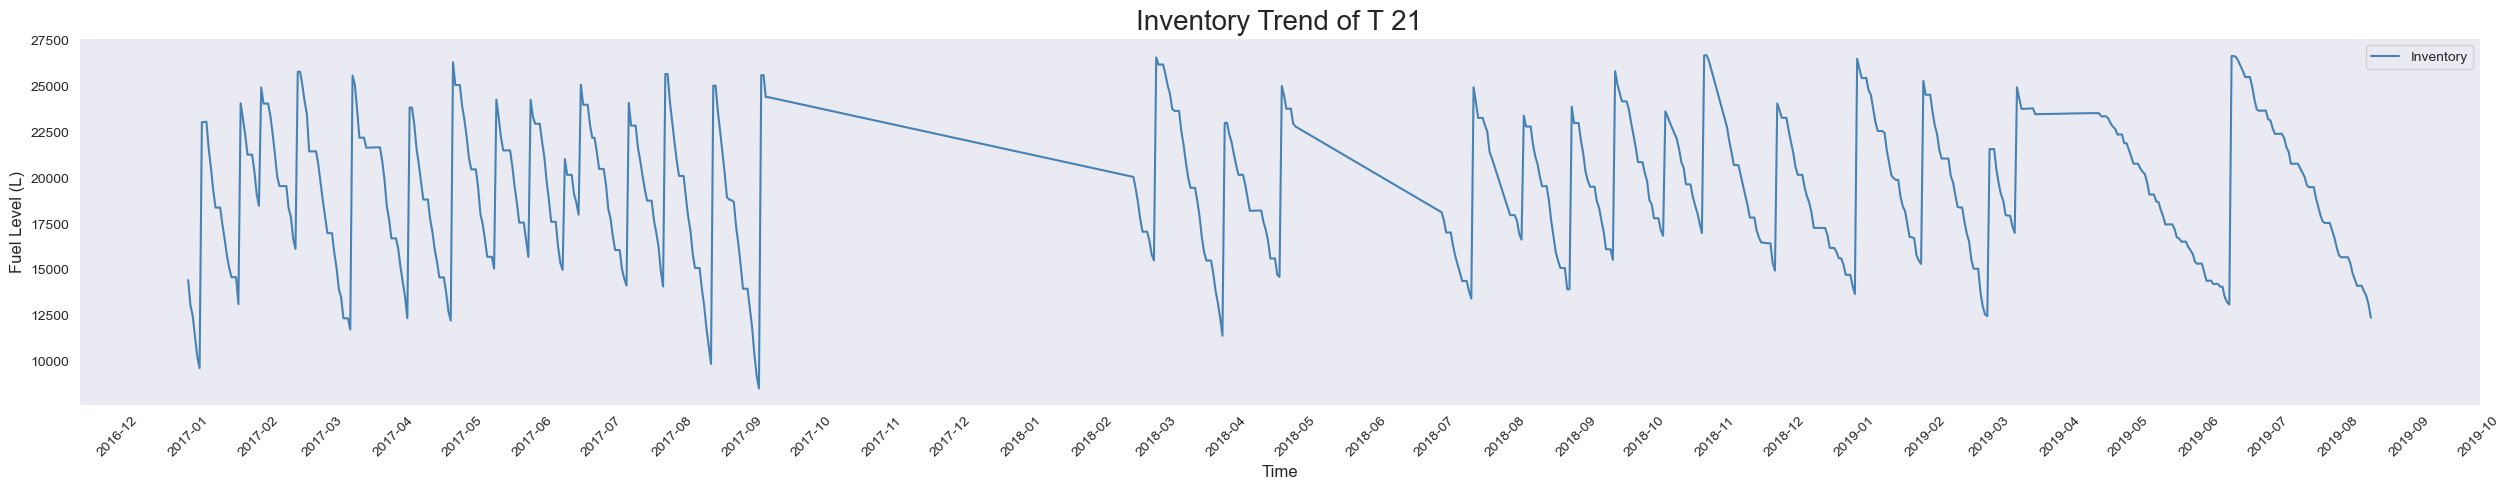

In [215]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 21')

**Visualization For T22**

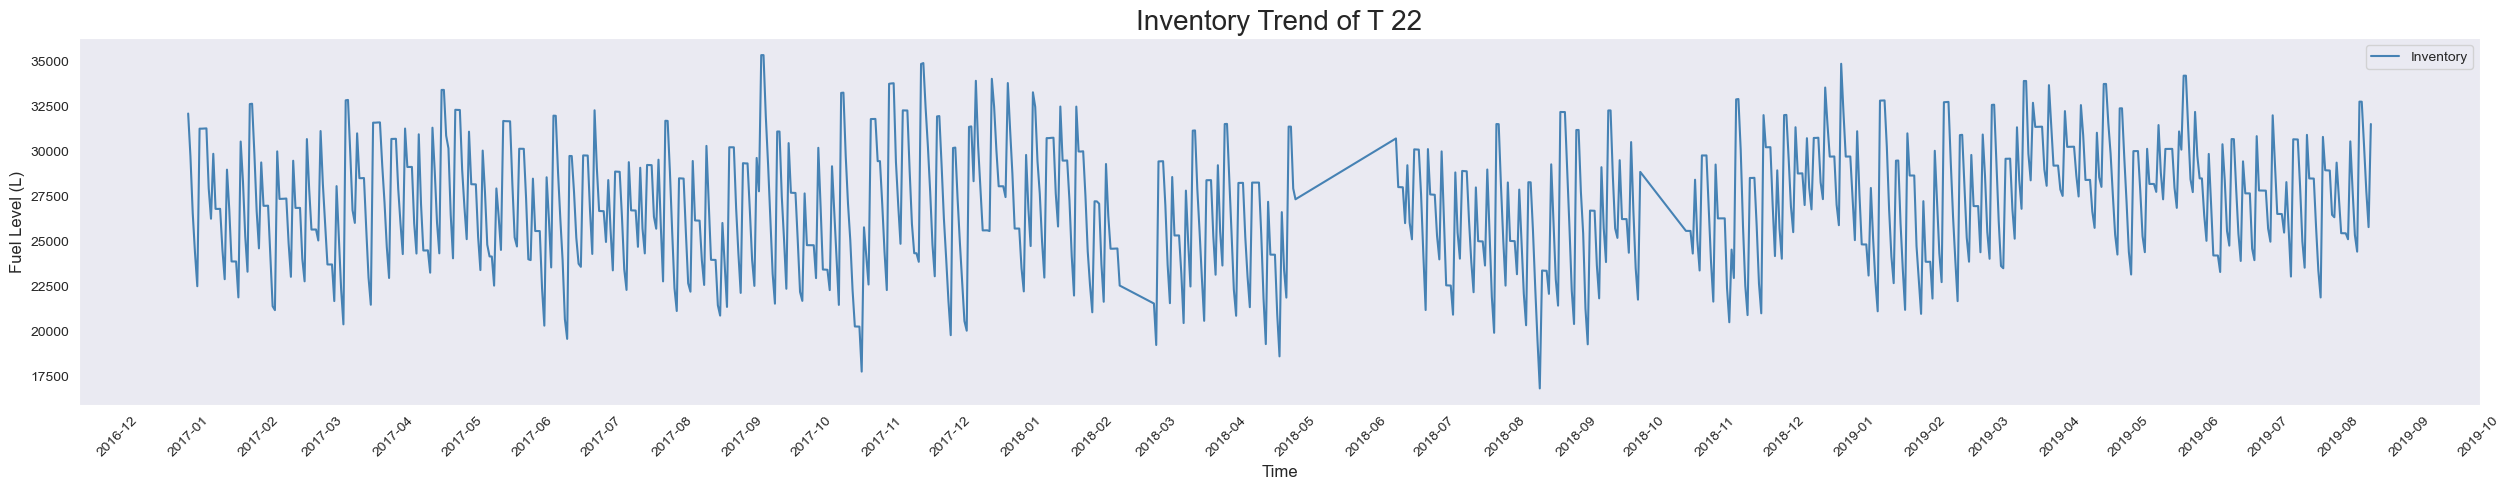

In [216]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 22')

**Visualization For T23**

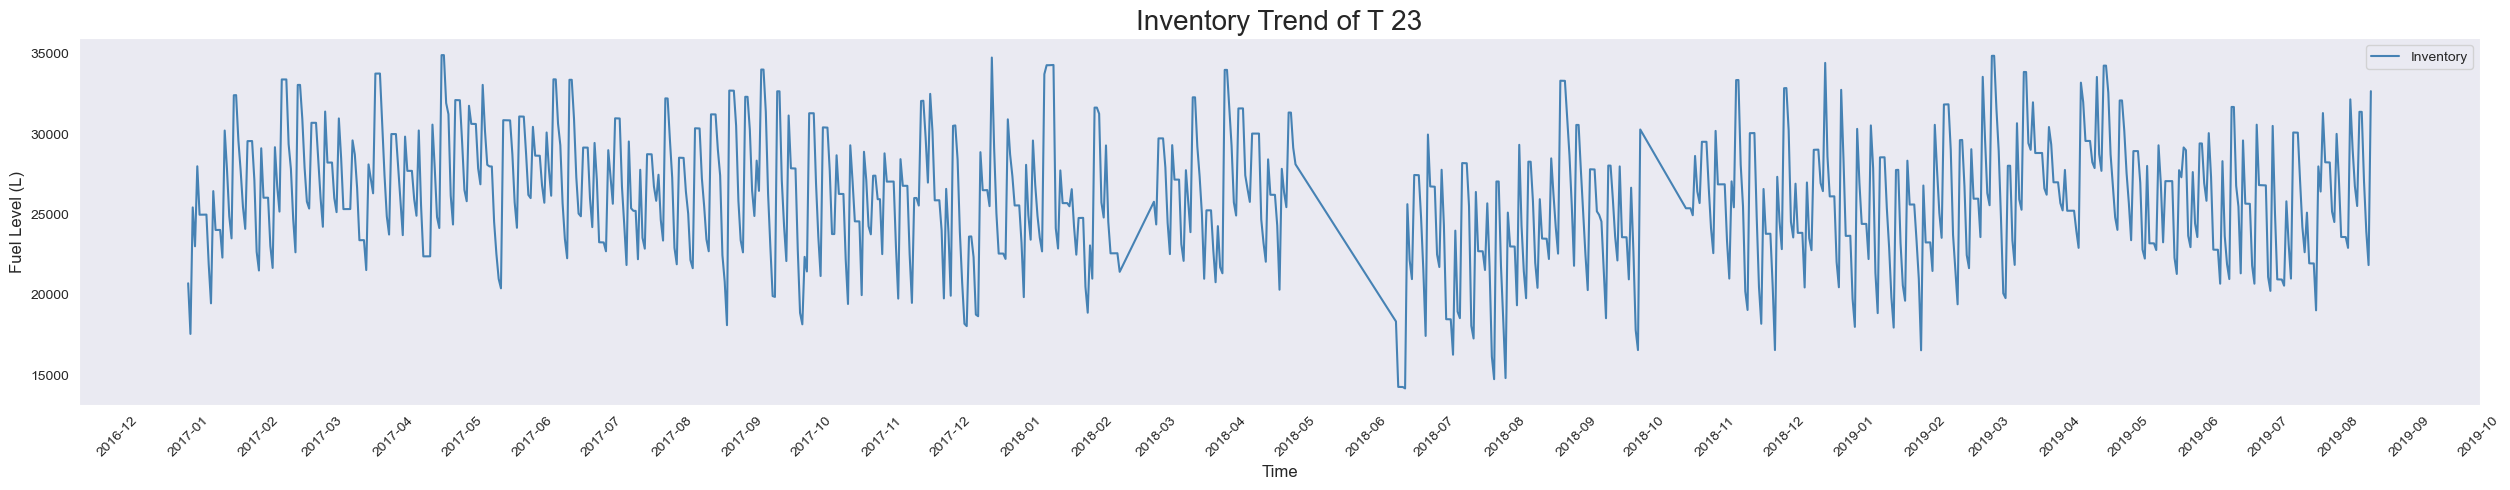

In [217]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 23')

**Visualization For T24**

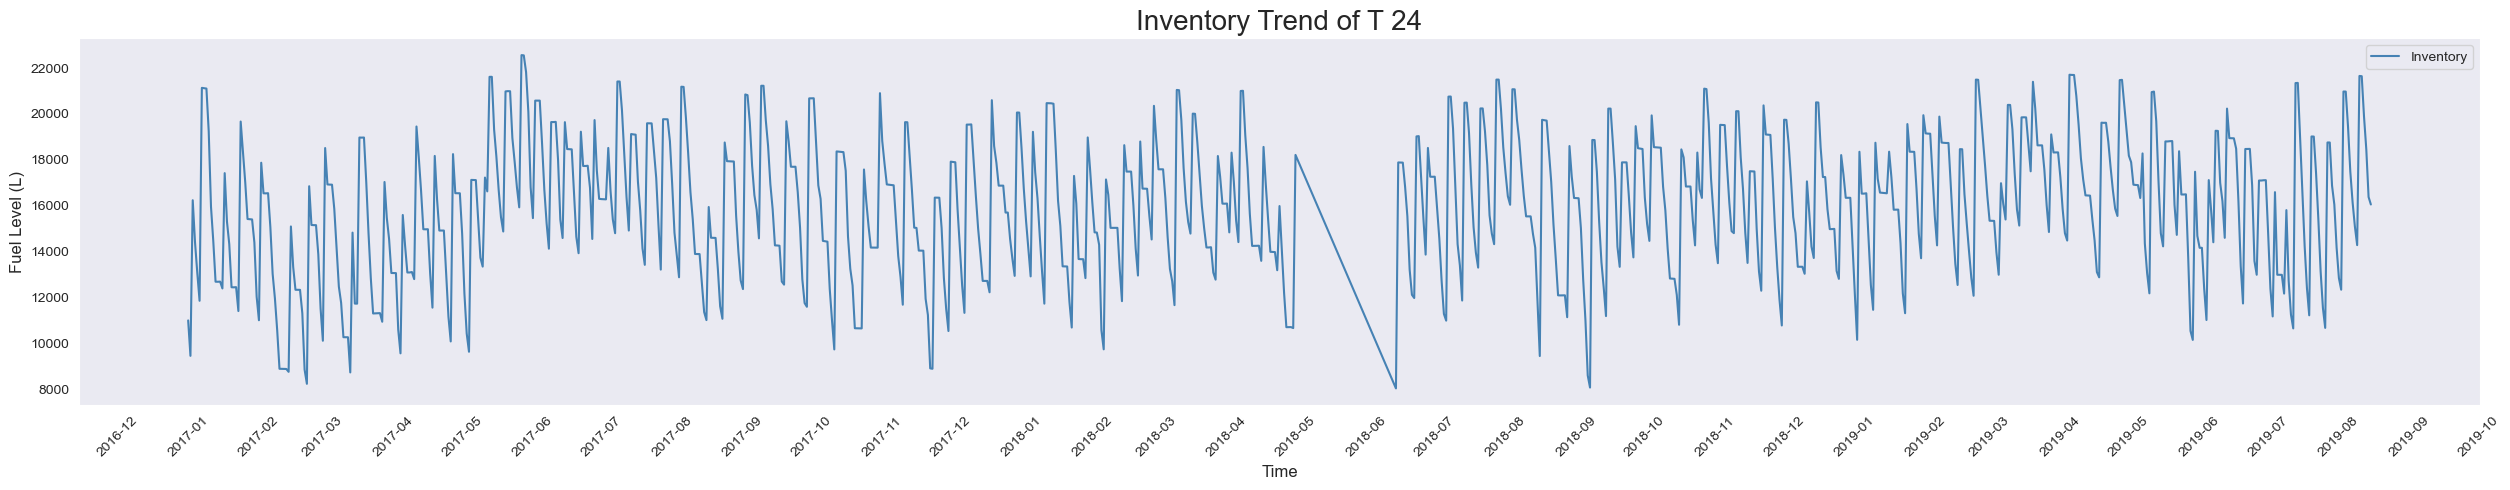

In [218]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 24')

**Visualization For T25**

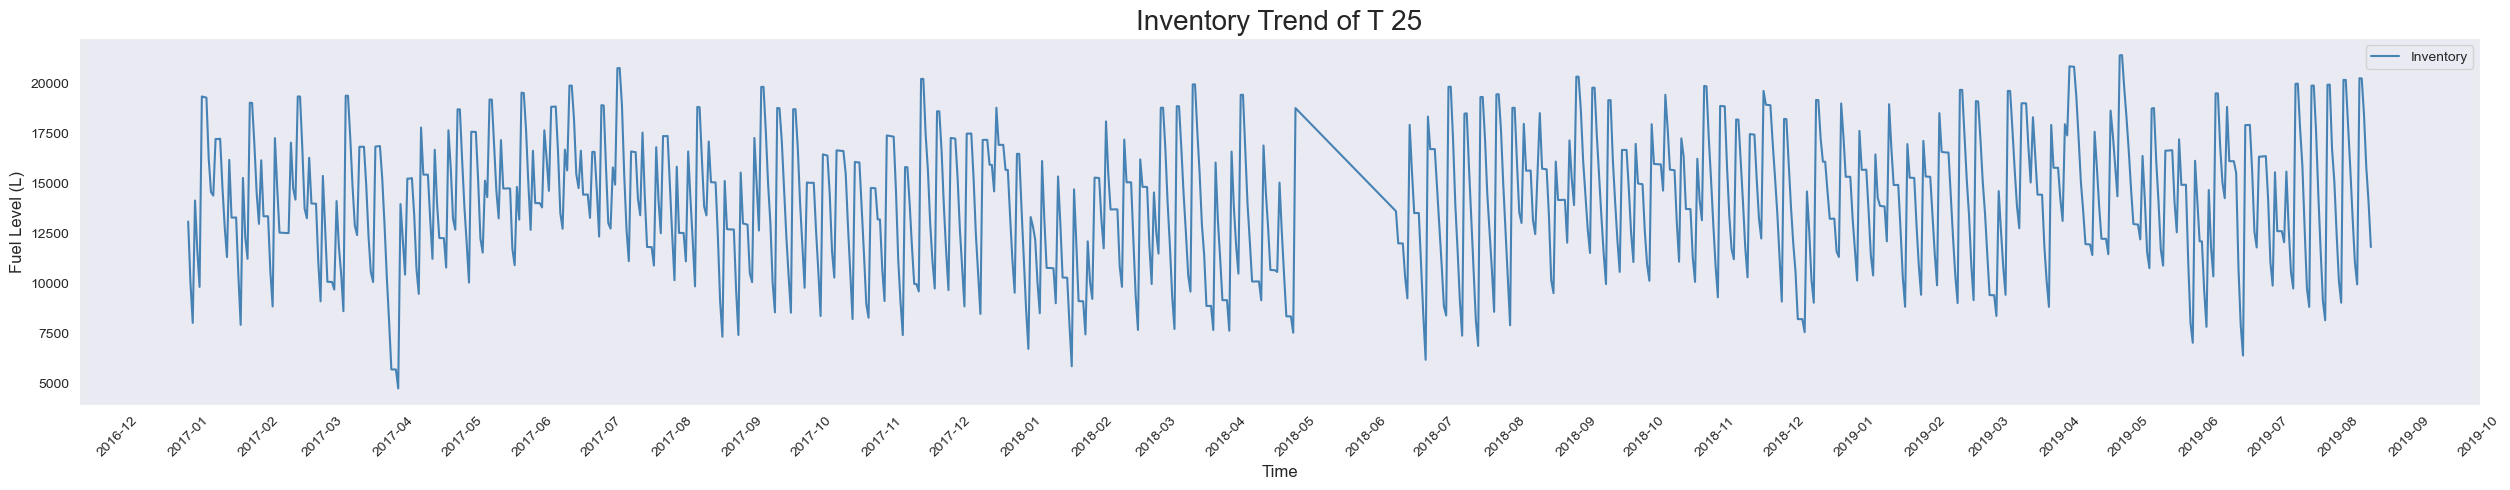

In [219]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 25')

**Visualization For T26**

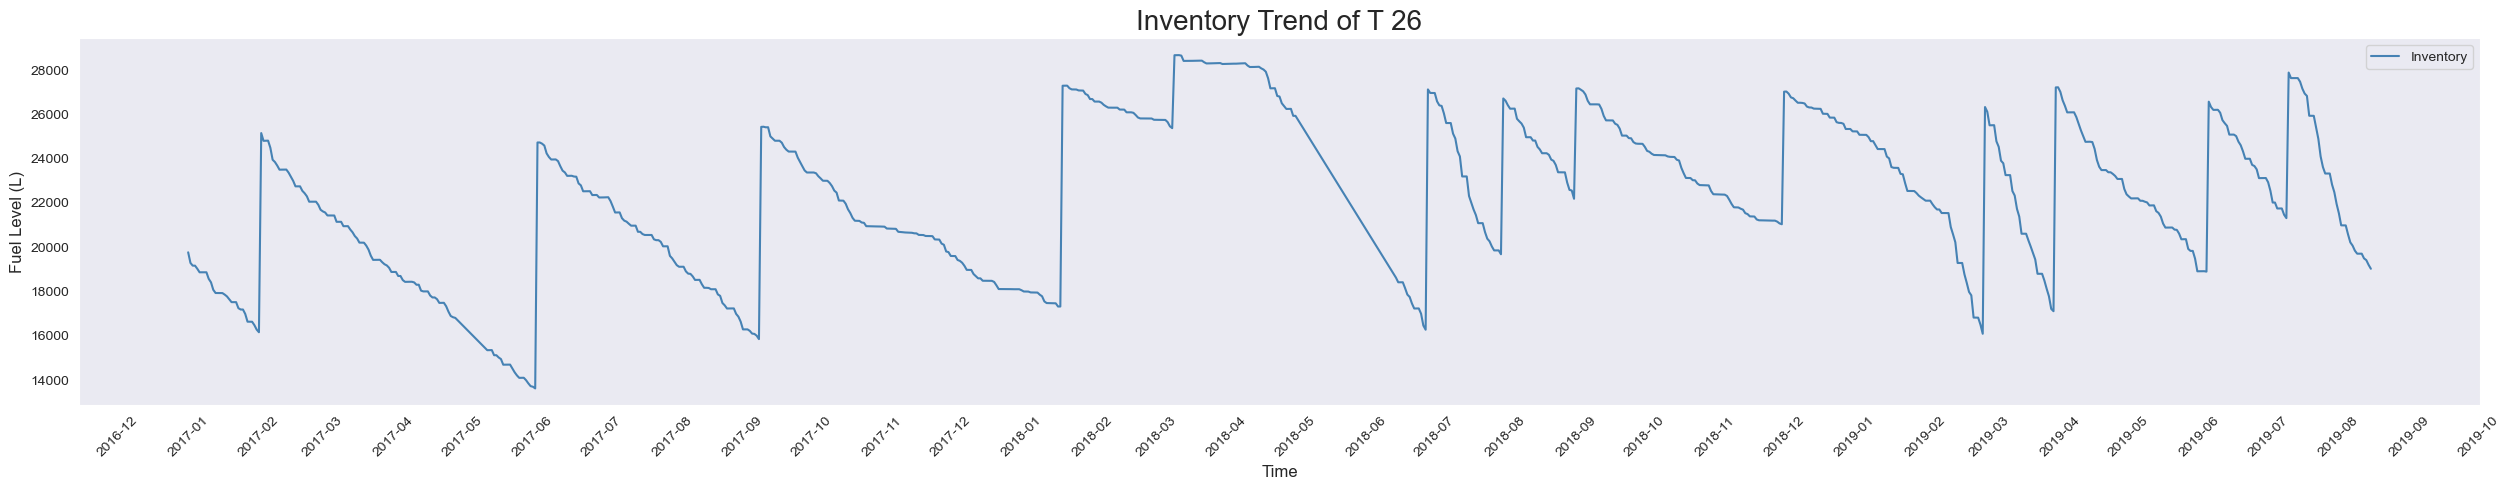

In [220]:
#Not effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 26')

**Visualization For T27**

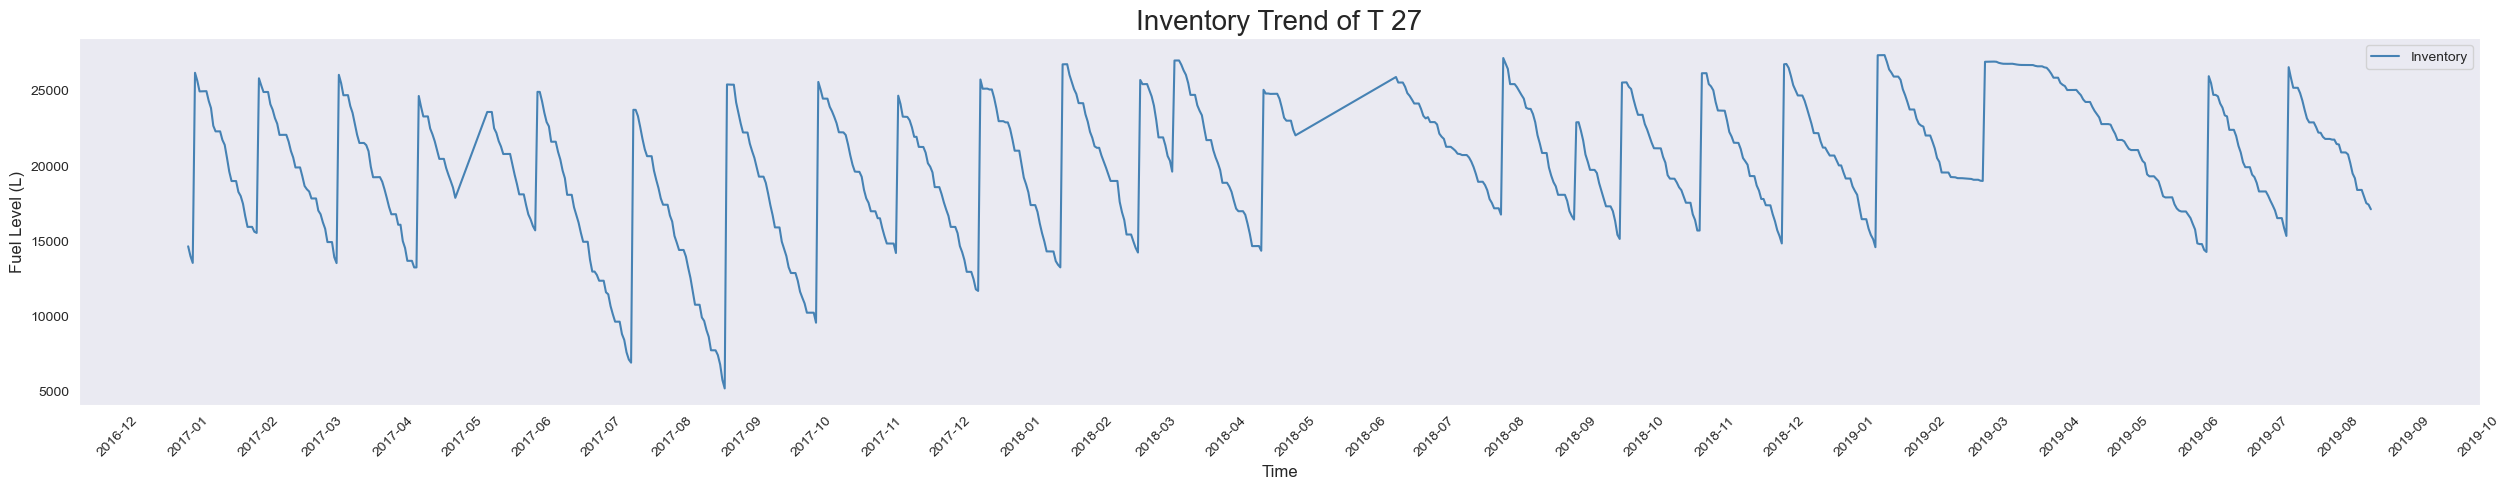

In [221]:
#Not effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 27')

**Visualization For T28**

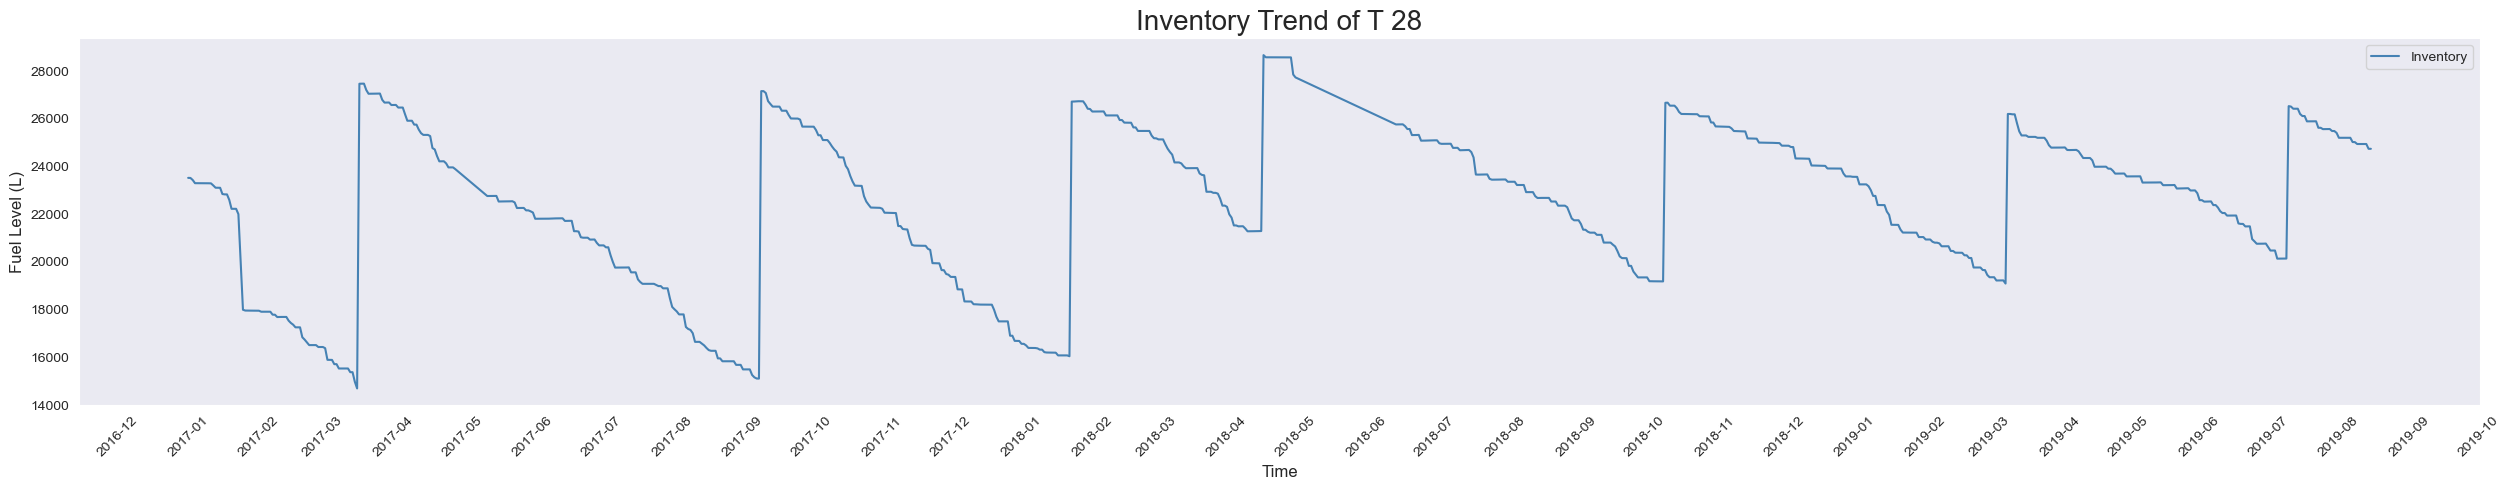

In [222]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 28')

**Visualization For T29**

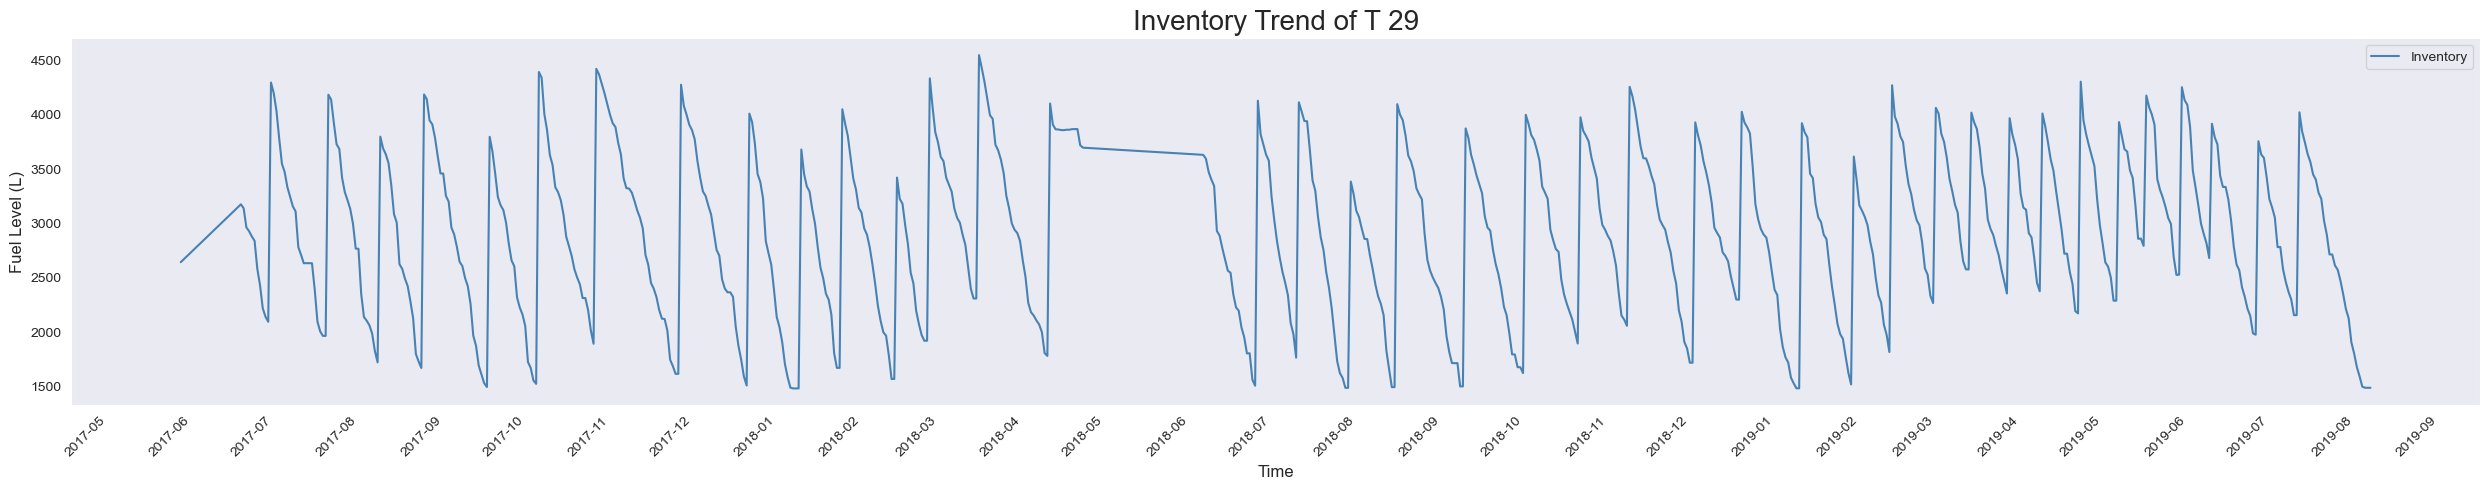

In [223]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 29')

**Visualization For T30**

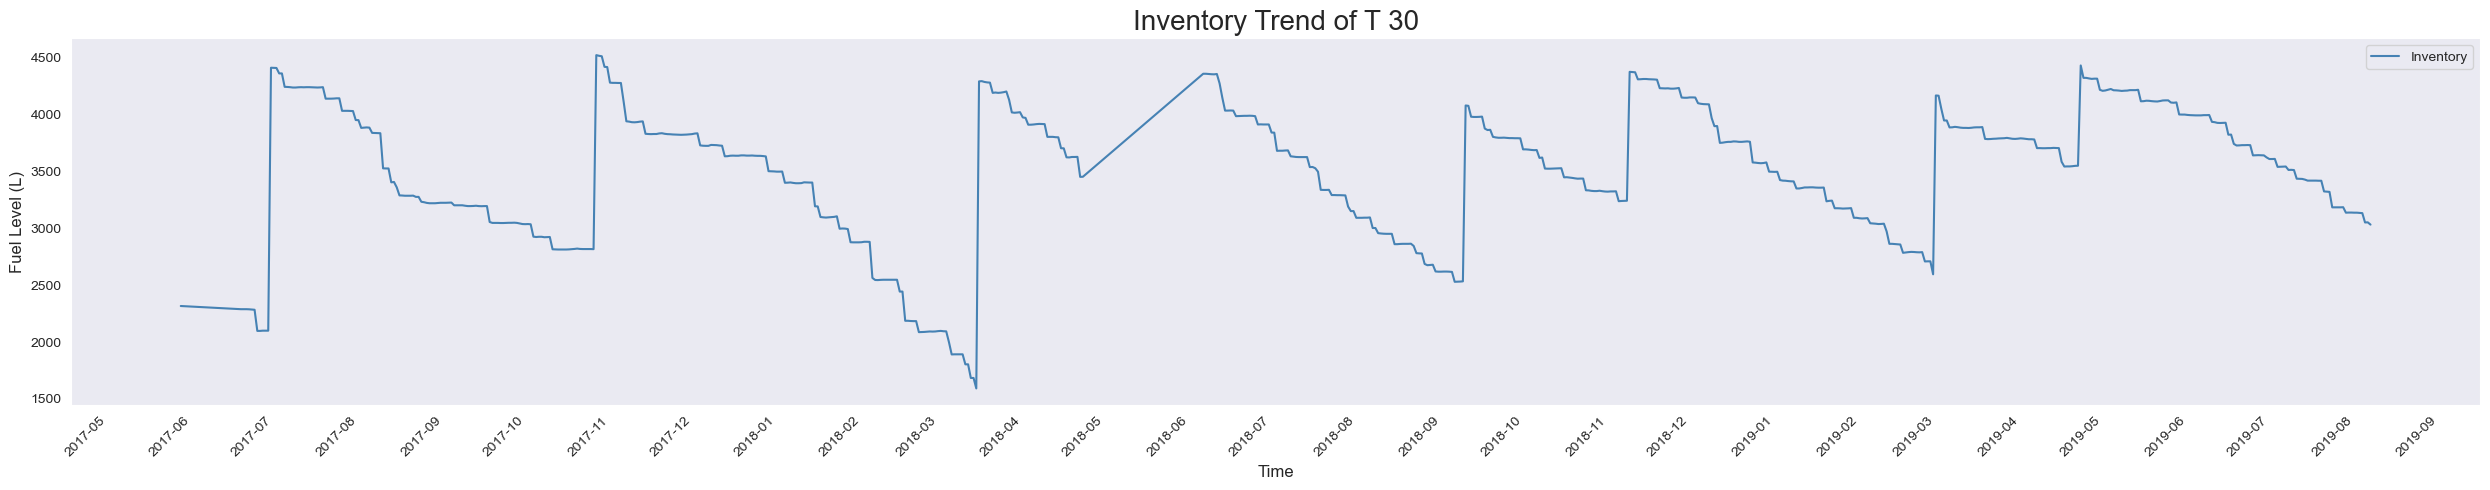

In [224]:
#Effective Inventory Practice
trend(Fuel_Levels_wo_d, 'T 30')

**Visualization For T31**

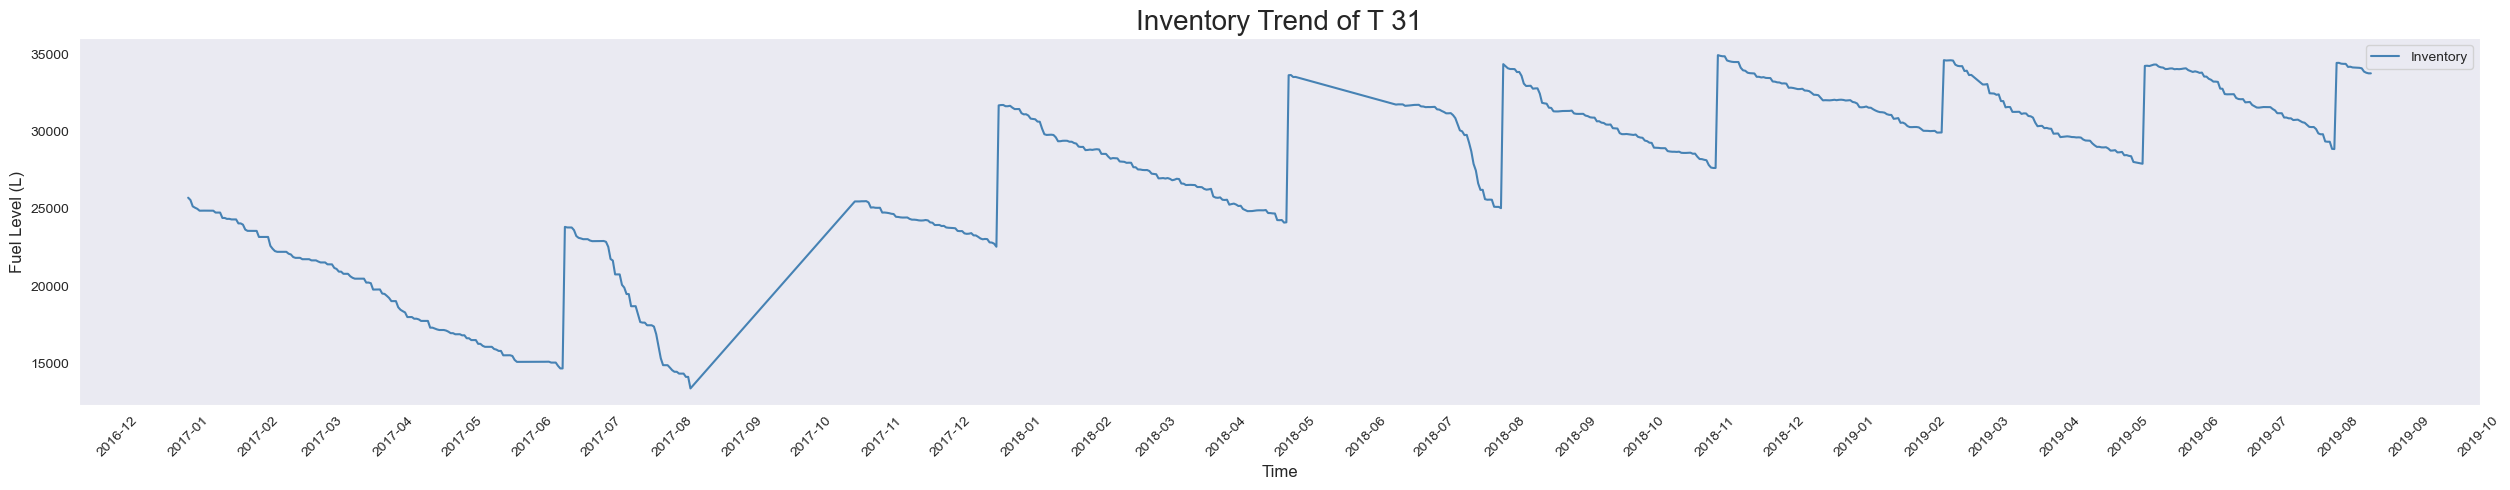

In [225]:
#Starts at constant stockouts, ends with effectivness
trend(Fuel_Levels_wo_d, 'T 31') #starts at stockout ends with effectivness

**Visualization For T32**

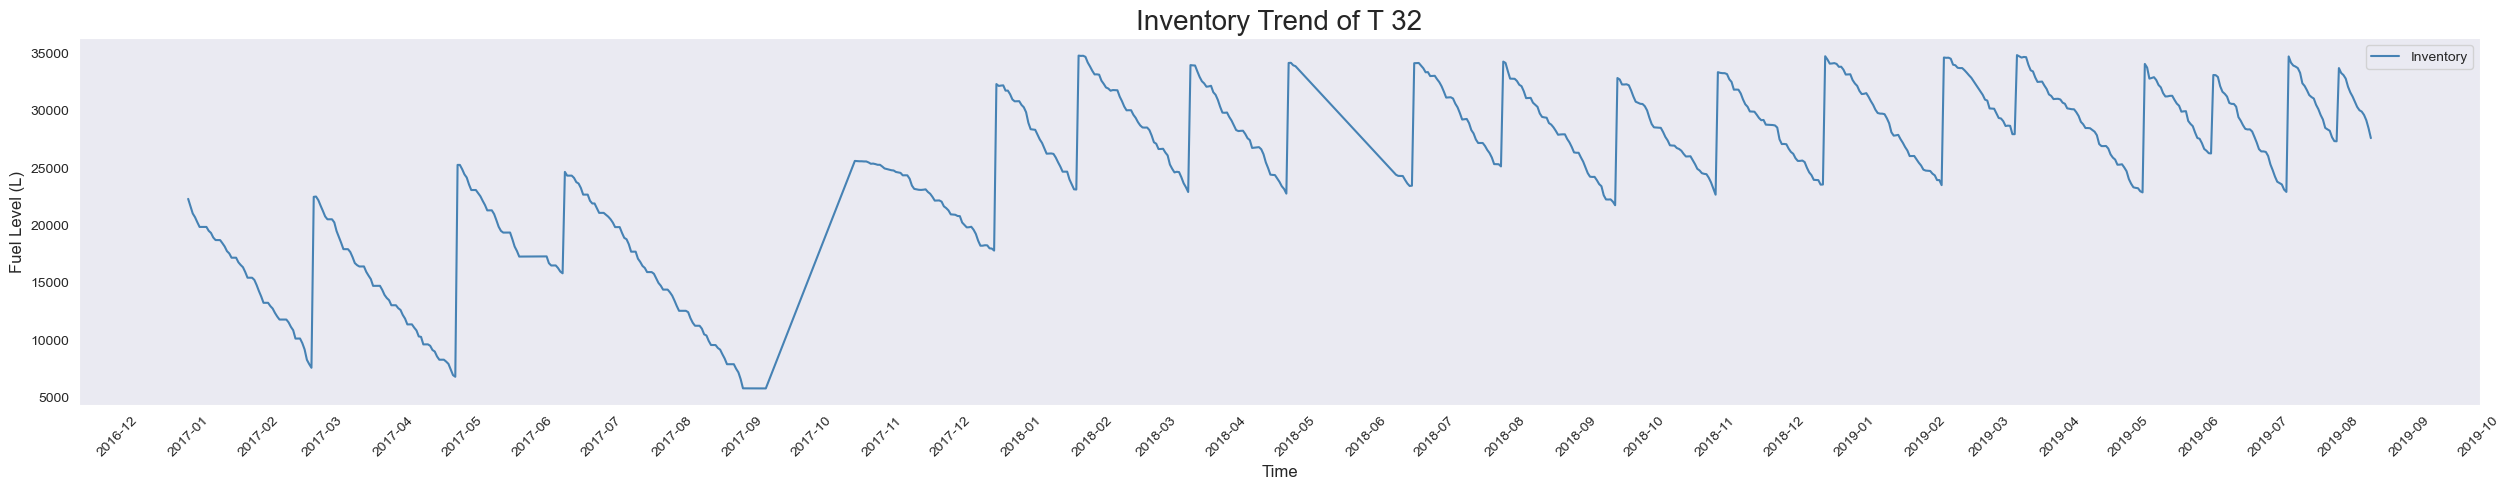

In [226]:
#Starts at stockout ends with effectivness
trend(Fuel_Levels_wo_d, 'T 32')

**Based on the invoices id dataset and the visualizations, we concluded that stations with a higher ID count also have more frequency in the visualizations. Station 8 has the lowest frequency while station 1 has the highest frequency. That means station 1 purchases inventory more frequently than station 8.**

##  Stations with Effective Inventory Management Practices and those at Risk of Stockouts
**Station 1:** Tanks 10 and 13 do not have effetive inventory managment. They have long periods of risk of stockout. All other tanks have effevtive inventory managment. 

**Station 2:** Has effetvie invenotry managment. Consistent purchasing patterns and rarley is at risk of stock out. 

**Station 3:** Not effective. Consistently at risk of stockout with inconsistent purchasing patterns.

**Station 4:** Generally effective. Few occasions of risk at stockout.

**Station 5:** Generally effective. Has ocasional risk of stock out, but purchasing patterns doesnt occur often.

**Station 6:** Generally not effective. At risk of stockout mulitple times.

**Station 7:** We determined inventory managment is not effective due to mulitple risks of stockout.

**Station 8:** Muliple risks of stockout to start, becomes more effetcive over time. 

**NOTE:** Considering the large volume of data which has negative impact on the visualization outcome,we create column 'date' and populate 'Fuel Level' the minimum inventory volumn of each day for later supply analysis.


**The following table is required to analyze the current purchasing pattern:**

In [227]:
Gas_per = Updated_Invoices_wo_d.groupby(["Gas Station Location", "Tank ID"])["Invoice ID"].count()
Gas_per

Gas Station Location  Tank ID
1                     T 10       1361
                      T 11       1361
                      T 12       1361
                      T 13       1361
                      T 14       1361
                      T 15       1361
2                     T 16        632
                      T 17        632
                      T 18        632
                      T 19        632
3                     T 20         80
                      T 21         80
4                     T 22        356
                      T 23        356
5                     T 24        280
                      T 25        280
6                     T 26         42
                      T 27         42
                      T 28         42
7                     T 29         52
                      T 30         52
8                     T 31         28
                      T 32         28
Name: Invoice ID, dtype: int64

## Question 2

**Propose strategies to improve fuel order quantities and save costs**

**Use the total tank capacity for each location and fuel type to determine the highest
applicable discount rate**

In [228]:
#creating the function for fuel type in tank
tank= pd.read_csv("Tanks-1.csv")
tank['Fuel Type'] = tank['Tank Type'].apply(
    lambda x: 'G' if x in ['U', 'P'] else ('D' if x == 'D' else np.nan)
)
tank.head()

,Tank ID,Tank Location,Tank Number,Tank Type,Tank Capacity,Fuel Type
0,T 10,1,1,U,40000,G
1,T 11,1,2,U,40000,G
2,T 12,1,3,D,40000,D
3,T 13,1,4,P,40000,G
4,T 14,1,5,U,40000,G


In [229]:
station_max = tank.groupby(["Tank Location", "Fuel Type"])["Tank Capacity"].sum().reset_index(name = "Total Tank Capacity")
station_max

,Tank Location,Fuel Type,Total Tank Capacity
0,1,D,80000
1,1,G,160000
2,2,D,110000
3,2,G,110000
4,3,D,30000
5,3,G,30000
6,4,D,40000
7,4,G,40000
8,5,D,25000
9,5,G,25000


In [230]:
def discount(x):
 if x<= 15000:
    return 0
 elif x <= 25000:
    return 0.02
 elif x <= 40000:
    return 0.03
 elif x > 40000:
    return 0.04
station_max['Cost_Saving']=station_max['Total Tank Capacity'].apply(discount)
display(station_max)

,Tank Location,Fuel Type,Total Tank Capacity,Cost_Saving
0,1,D,80000,0.04
1,1,G,160000,0.04
2,2,D,110000,0.04
3,2,G,110000,0.04
4,3,D,30000,0.03
5,3,G,30000,0.03
6,4,D,40000,0.03
7,4,G,40000,0.03
8,5,D,25000,0.02
9,5,G,25000,0.02


**Calculate a 7-day inventory threshold based on the average daily consumption for each location and fuel type**

In [231]:
##Calculate the total number of days
from datetime import datetime
startdate=datetime(2017,1,2)
enddate=datetime(2019,8,15)
a=str(enddate-startdate)[0:3]
print(a)

955


In [232]:
station_max.rename(columns = {"Tank Location": "Gas Station Location"}, inplace = True)
subset_1 = Invoices.groupby(['Gas Station Location', 'Fuel Type'])['Amount Purchased'].sum().div(955).mul(7).reset_index(name = "Inventory_Threshhold")
subset_1

,Gas Station Location,Fuel Type,Inventory_Threshhold
0,1,D,35714.352067
1,1,G,79647.621479
2,2,D,25367.851996
3,2,G,20688.582651
4,3,D,3165.137005
5,3,G,3104.325227
6,4,D,11965.737198
7,4,G,11571.020348
8,5,D,5949.882371
9,5,G,9871.193416


**Compute potential savings by optimizing order quantities to maximize discounts while
maintaining sufficient inventory**

Gas stations could maximize their discounts by purchasing gas as much as possible each single time. However, they should purchase again before their inventory drop below their 7-day inventory threshold. So the quantity they should purchase is the difference between their total capacity and 7-day inventory threshold

In [233]:
#Before our analysis, we merge dataframe subset_1 and station_max
optimized_qty = subset_1.merge(station_max, on =['Gas Station Location','Fuel Type'])
optimized_qty['order_amount'] = round(optimized_qty['Total Tank Capacity'] - optimized_qty['Inventory_Threshhold'],2)
optimized_qty['potential savings']= round(optimized_qty['order_amount'] * optimized_qty['Cost_Saving'],2)
optimized_qty

,Gas Station Location,Fuel Type,Inventory_Threshhold,Total Tank Capacity,Cost_Saving,order_amount,potential savings
0,1,D,35714.352067,80000,0.04,44285.65,1771.43
1,1,G,79647.621479,160000,0.04,80352.38,3214.10
2,2,D,25367.851996,110000,0.04,84632.15,3385.29
3,2,G,20688.582651,110000,0.04,89311.42,3572.46
4,3,D,3165.137005,30000,0.03,26834.86,805.05
5,3,G,3104.325227,30000,0.03,26895.67,806.87
6,4,D,11965.737198,40000,0.03,28034.26,841.03
7,4,G,11571.020348,40000,0.03,28428.98,852.87
8,5,D,5949.882371,25000,0.02,19050.12,381.00
9,5,G,9871.193416,25000,0.02,15128.81,302.58


**Offer specific recommendations to improve inventory policies and estimate potential cost
savings for each location**

**For Station 7, which does not have discount:** Maintain saftey stock and make sure inventory doesnt drop lower than the saftey stock.

**For other stations which can have discount:** These stations have the highest capcity so they are eligible to order more gas and get a higher discount. We suggest them to decrease their purchase frequency but increase the volume they buy for each time so that they can have higher discount. Considering the risk of stock out, we think they should re-purchase each time their inventory drop to the inventory treshold.



## Question3

**Analyze whether a specific day of the week consistently offers lower fuel prices**

In [234]:
##Calculate price-per-liter(ppl)
Invoices['ppl']=round(Invoices['Gross Purchase Cost']/Invoices['Amount Purchased'],2)
Invoices

,Invoice Date,Invoice ID,Gas Station Location,Gross Purchase Cost,Amount Purchased,Fuel Type,Gas Station Name,Gas Station Address,Gas Station Latitude,Gas Station Longitude,ppl
0,1/2/2017,10000.0,1,7570.82000,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.234670,-79.836510,1.15
1,1/2/2017,10001.0,1,12491.85300,9338.736,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.234670,-79.836510,1.34
2,1/2/2017,10002.0,2,17034.34500,13377.824,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.27
3,1/2/2017,10003.0,2,12616.77153,9432.112,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.34
4,1/2/2017,10004.0,4,11363.80082,9139.200,D,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.24
...,...,...,...,...,...,...,...,...,...,...,...
2826,8/14/2019,12826.0,2,14418.62669,8182.960,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.76
2827,8/14/2019,12827.0,2,7570.82000,4296.640,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.76
2828,8/14/2019,12828.0,4,8706.44300,6352.416,G,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.37
2829,8/14/2019,12829.0,4,13252.72041,7521.264,D,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.76


**Examine the distribution of price-per-liter rates by day of the week**

/var/folders/9x/hwj7pzhs1g7926b3t9ddsmcw0000gn/T/ipykernel_59272/1855424907.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes.set(xticklabels=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])


[[Text(0, 0, 'Monday'),
  Text(1, 0, 'Tuesday'),
  Text(2, 0, 'Wednesday'),
  Text(3, 0, 'Thursday'),
  Text(4, 0, 'Friday'),
  Text(5, 0, 'Saturday')]]

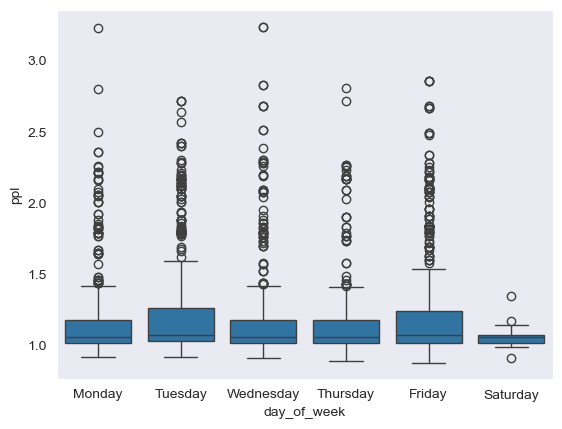

In [237]:
## Transfer our form of date for later analysis
Invoices['date'] = pd.to_datetime(Invoices['Invoice Date'])
Invoices =Invoices.sort_values(by='date', ascending=True)
Invoices['day_of_week'] = Invoices['date'].dt.day_name()

##Then Summarize data and shows distribution of price-per-liter rates by day of the week:import seaborn as sns
import seaborn as sns
sns.set_style('dark')
axes = sns.boxplot(data=Invoices,x='day_of_week',y='ppl')
axes.set(xlabel='day_of_week')
axes.set(xticklabels=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])

**Identify the day with the lowest historical rates**

In [238]:
Invoices.groupby('day_of_week')['ppl'].mean().nsmallest(1)

day_of_week
Saturday    1.071538
Name: ppl, dtype: float64

**Calculate additional savings if purchases were consistently made on the identified day**

In [239]:
Invoices['cheap_price']=round(Invoices['Amount Purchased']* 1.071538,2)
Invoices['add_saving']=round(Invoices['Gross Purchase Cost']-Invoices['cheap_price'],2)
Invoices

,Invoice Date,Invoice ID,Gas Station Location,Gross Purchase Cost,Amount Purchased,Fuel Type,Gas Station Name,Gas Station Address,Gas Station Latitude,Gas Station Longitude,ppl,date,day_of_week,cheap_price,add_saving
0,1/2/2017,10000.0,1,7570.82000,6609.600,G,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.234670,-79.836510,1.15,2017-01-02,Monday,7082.44,488.38
1,1/2/2017,10001.0,1,12491.85300,9338.736,D,EastMount,"386 Upper Gage Ave, Hamilton, ON L8V 4H9, Canada",43.234670,-79.836510,1.34,2017-01-02,Monday,10006.81,2485.04
2,1/2/2017,10002.0,2,17034.34500,13377.824,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.27,2017-01-02,Monday,14334.85,2699.50
3,1/2/2017,10003.0,2,12616.77153,9432.112,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.34,2017-01-02,Monday,10106.87,2509.90
4,1/2/2017,10004.0,4,11363.80082,9139.200,D,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.24,2017-01-02,Monday,9793.00,1570.80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2829,8/14/2019,12829.0,4,13252.72041,7521.264,D,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.76,2019-08-14,Wednesday,8059.32,5193.40
2826,8/14/2019,12826.0,2,14418.62669,8182.960,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.76,2019-08-14,Wednesday,8768.35,5650.28
2828,8/14/2019,12828.0,4,8706.44300,6352.416,G,Chedoke,"16 McMaster Ave, Dundas, ON L9H 0A8, Canada",43.261849,-79.937057,1.37,2019-08-14,Wednesday,6806.86,1899.58
2827,8/14/2019,12827.0,2,7570.82000,4296.640,D,Eastgate,"75 Centennial Pkwy N E5, Hamilton, ON L8E 2P2,...",43.230700,-79.763930,1.76,2019-08-14,Wednesday,4604.01,2966.81


## Question 4

**Assess whether increasing tank capacity at certain locations would be beneficial**

**Assume the cost of adding a new tank**

#### According to commatank.com (https://www.commtank.com/ufaqs/how-much-does-a-gas-station-fuel-tank-cost/), the average cost for a double-walled fiberglass fuel tank for gas stations is 25,000 30,000 dollar. We assume the cost of adding a new tank is $28,000

**Estimate the cost-benefit of increased capacity over a 5-year period**

In [240]:
# We decided to add the fuel type that has the largest potential savings. 
#Then we add a tank to each location and match the largest tank capacity in that location.
#Find out the fuel type and related tank type that has highest potential savings for each Gas station:
optimized_1= optimized_qty.groupby("Gas Station Location").apply(
    lambda x: x.loc[x['potential savings'].idxmax(),'Fuel Type']
).tolist()
print(optimized_1)

['G', 'G', 'G', 'G', 'D', 'G', 'D', 'D']


/var/folders/9x/hwj7pzhs1g7926b3t9ddsmcw0000gn/T/ipykernel_59272/1956080476.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  optimized_1= optimized_qty.groupby("Gas Station Location").apply(


In [241]:
capacity_1= tank.groupby("Tank Location").apply(
    lambda x: x.loc[x['Tank Capacity'].idxmax(),'Tank Capacity']
).tolist()
print(capacity_1)

[40000, 70000, 30000, 40000, 25000, 30000, 5000, 40000]


/var/folders/9x/hwj7pzhs1g7926b3t9ddsmcw0000gn/T/ipykernel_59272/806361488.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  capacity_1= tank.groupby("Tank Location").apply(


In [242]:
# Add the fuel type that has the largest potential savings. 
# Then add a tank to each location and match the largest tank capacity in that location. 
# create a new data frame with the new tanks for each station, and then concatenate that with the existing dataset  
new_data_frame = pd.DataFrame(columns = tank.columns)
new_data_frame

# Add values for some of the columns 
new_data_frame["Tank ID"] = ["T 33", "T 34", "T 35", "T 36", "T 37", "T 38", "T 39", "T 40"]
new_data_frame["Tank Location"] = [1,2,3,4,5,6,7,8]

# Creating a new dataframe with the Fuel type that has largest potential cost saving and biggest capacity:
import numpy as np
new_data_frame["Tank Capacity"] = capacity_1
new_data_frame["Fuel Type"] = optimized_1
new_data_frame['Tank Capacity']=pd.to_numeric(new_data_frame['Tank Capacity'])
new_data_frame['Tank Location']=pd.to_numeric(new_data_frame['Tank Location'])
new_data_frame.columns = new_data_frame.columns.get_level_values(0)

new_capacity = pd.concat([tank, new_data_frame], axis=0, ignore_index=True)
new_capacity

,Tank ID,Tank Location,Tank Number,Tank Type,Tank Capacity,Fuel Type
0,T 10,1,1,U,40000,G
1,T 11,1,2,U,40000,G
2,T 12,1,3,D,40000,D
3,T 13,1,4,P,40000,G
4,T 14,1,5,U,40000,G
5,T 15,1,6,D,40000,D
6,T 16,2,1,U,70000,G
7,T 17,2,2,D,40000,D
8,T 18,2,3,U,40000,G
9,T 19,2,4,D,70000,D


In [243]:
## Get the new total capacity of each station for the 5 years in the future:
added_tank=new_capacity.groupby(['Tank Location','Fuel Type'])['Tank Capacity'].sum().reset_index(name='Tank Capacity')
added_tank.rename(columns = {"Tank Location": "Gas Station Location"}, inplace = True)
added_tank

,Gas Station Location,Fuel Type,Tank Capacity
0,1,D,80000
1,1,G,200000
2,2,D,110000
3,2,G,180000
4,3,D,30000
5,3,G,60000
6,4,D,40000
7,4,G,80000
8,5,D,50000
9,5,G,25000


In [244]:
## Calculate the cost savings for the next five years for each tank
added_qty = subset_1.merge(added_tank, on =['Gas Station Location','Fuel Type'])
## Calculate the cost saving for each tank in every week based on the discount policy and consumption we did before:
added_qty['Cost_Saving'] = added_qty['Tank Capacity'].apply(discount)
added_qty['order_amount'] = round(added_qty['Tank Capacity'] - added_qty['Inventory_Threshhold'],2)
## every year has 52 weeks, so the total saving for the 5 years in the future is: 
added_qty['potential savings']= round(added_qty['order_amount'] * added_qty['Cost_Saving'] * 5 * 52 ,2)

## Calculate the potential savings if we do not add a new tank:
added_qty['if_not_add']=round(optimized_qty['potential savings']*5*52,2)
## Substract the difference of potential savings between with and without adding a new tank:
added_qty['benefit']=added_qty['potential savings']-added_qty['if_not_add']

added_qty

,Gas Station Location,Fuel Type,Inventory_Threshhold,Tank Capacity,Cost_Saving,order_amount,potential savings,if_not_add,benefit
0,1,D,35714.352067,80000,0.04,44285.65,460570.76,460571.8,-1.04
1,1,G,79647.621479,200000,0.04,120352.38,1251664.75,835666.0,415998.75
2,2,D,25367.851996,110000,0.04,84632.15,880174.36,880175.4,-1.04
3,2,G,20688.582651,180000,0.04,159311.42,1656838.77,928839.6,727999.17
4,3,D,3165.137005,30000,0.03,26834.86,209311.91,209313.0,-1.09
5,3,G,3104.325227,60000,0.04,56895.67,591714.97,209786.2,381928.77
6,4,D,11965.737198,40000,0.03,28034.26,218667.23,218667.8,-0.57
7,4,G,11571.020348,80000,0.04,68428.98,711661.39,221746.2,489915.19
8,5,D,5949.882371,50000,0.04,44050.12,458121.25,99060.0,359061.25
9,5,G,9871.193416,25000,0.02,15128.81,78669.81,78670.8,-0.99


In [245]:
benefit_table = added_qty.groupby('Gas Station Location')['benefit'].sum().reset_index(name='benefit')
## Consider the cost of adding a tank($28,000) to each station:
benefit_table['cost_benefit']=benefit_table['benefit']-28000
benefit_table 

,Gas Station Location,benefit,cost_benefit
0,1,415997.71,387997.71
1,2,727998.13,699998.13
2,3,381927.68,353927.68
3,4,489914.62,461914.62
4,5,359060.26,331060.26
5,6,311998.73,283998.73
6,7,0.00,-28000.00
7,8,518549.40,490549.40


**Identify locations that would benefit most from additional tanks**

In [246]:
benefit_table['cost_benefit'].max()

699998.13

**Location that Benefits the Most:** Gas station 2. We subtracted the potenital savings of each gas station with and without a new tank. We subtracted the cost of that new tank that we estimated (28,000 canadian dollars). We took the tank with the biggest difference to deicde which would be impacted the most.

# Further Discussion

### Cost structure optimization

**Economic Order Quantity(EOQ):** Tells you how much inventory to order

**Formula:** ((Demand * Ordering Cost Per Order)/Hold Cost per unit))^0.5

#### For our EOQ formula (https://www.investopedia.com/terms/e/economicorderquantity.asp), we are required to calculate the ordering cost. Thus, we are assuming that the order cost has been included in the price per litre. We will take an average of this and use that as the single cost of delivery. Aditionally, we are unable to find the fixed cost for each gas station based in canada as there is no data available to the public. Thus, we found an article: https://www.commtank.com/tank-articles/underground-storage-tanks-vs-aboveground-storage-tanks/ where the fixed cost for an underground fuel storage tank is $1,500 per year. We will be assuming this costs for the Candian ecosystem as well. Thus, we have muliplied this into the exchange rate.

In [247]:
#calculating the average price per litre value 
avg_ppl = round((Invoices['ppl'].mean()),2)
#Converted fixed cost of 1500 into Canadian Dollars (1500 * ~1.4)
fixed_cost = 2098.50

In [248]:
#Calculating EOQ
new_sub["Demand"] = round((new_sub["Safety Stock"].mul(52)),2)
new_sub["EOQ"] = round((2 * (new_sub["Demand"]*avg_ppl)/(new_sub["Total Tank Capacity"].div(1000))* fixed_cost) ** 0.5,2)
new_sub

,Gas Station Location,Fuel Type,Average Daily Consumption,Total Tank Capacity,Cost_Saving,Safety Stock,Reorder Point,Demand,EOQ
0,1,D,5102.05,80000,0.04,35714.35,51020.5,1857146.20,10857.76
1,1,G,11378.23,160000,0.04,79647.61,113782.3,4141675.72,11465.43
2,2,D,3623.98,110000,0.04,25367.86,36239.8,1319128.72,7803.86
3,2,G,2955.51,110000,0.04,20688.57,29555.1,1075805.64,7047.46
4,3,D,452.16,30000,0.03,3165.12,4521.6,164586.24,5278.35
5,3,G,443.48,30000,0.03,3104.36,4434.8,161426.72,5227.44
6,4,D,1709.39,40000,0.03,11965.73,17093.9,622217.96,8887.99
7,4,G,1653.00,40000,0.03,11571.00,16530.0,601692.00,8740.16
8,5,D,849.98,25000,0.02,5949.86,8499.8,309392.72,7927.70
9,5,G,1410.17,25000,0.02,9871.19,14101.7,513301.88,10211.24


### Operational efficiency upgrading

**Reorder Point (ROP):** According to datup.ai, (https://datup.ai/en/blog/reorder-point) ROP indicates when to place a new order to prevent stockouts. 

**Formula:** (Average Daily Consumption * Lead Time) + Safety Stock

In [250]:
#Reorder Point (ROP) Calculation
#We are assuming our lead time is 3 days
station_max.rename(columns = {"Tank Location": "Gas Station Location"}, inplace = True)
subset_1 = round((Invoices.groupby(['Gas Station Location', 'Fuel Type'])['Amount Purchased'].sum().div(955).reset_index(name = "Average Daily Consumption")),2)


In [251]:
#Reorder Point (ROP) Calculation
new_sub = subset_1.merge(station_max, on =['Gas Station Location','Fuel Type'])
new_sub["Safety Stock"] = new_sub["Average Daily Consumption"].mul(7)
lead_time = 3
new_sub["Reorder Point"] = round((new_sub["Average Daily Consumption"].mul(lead_time) + new_sub["Safety Stock"]),2)
new_sub

,Gas Station Location,Fuel Type,Average Daily Consumption,Total Tank Capacity,Cost_Saving,Safety Stock,Reorder Point
0,1,D,5102.05,80000,0.04,35714.35,51020.5
1,1,G,11378.23,160000,0.04,79647.61,113782.3
2,2,D,3623.98,110000,0.04,25367.86,36239.8
3,2,G,2955.51,110000,0.04,20688.57,29555.1
4,3,D,452.16,30000,0.03,3165.12,4521.6
5,3,G,443.48,30000,0.03,3104.36,4434.8
6,4,D,1709.39,40000,0.03,11965.73,17093.9
7,4,G,1653.00,40000,0.03,11571.00,16530.0
8,5,D,849.98,25000,0.02,5949.86,8499.8
9,5,G,1410.17,25000,0.02,9871.19,14101.7
